# Hotel Booking Cancellation — Model Evaluation & Business Action

## What this notebook delivers

Two batch outputs for the hotel operations team, produced from the
frozen finalist models of this project:

1. **Hotel-level forecast** — nightly expected check-ins and expected
   room-nights occupied, per hotel. For staff planning (front desk,
   housekeeping, F&B).
2. **Booking-level risk shortlist** — top-K risky bookings per cutoff
   day for operations to contact. Workload scales with the team's
   actual contact budget.

Along the way it picks the finalist models, picks a calibration method,
picks an operating workload, and measures everything on the held-out
Test cohort.

## Where this notebook fits in the project

```text
Data pipeline                    Model pipeline                 Evaluation pipeline (THIS NOTEBOOK)
──────────────                   ──────────────                 ────────────────────────────────────
Bronze → Silver → Gold           Experiment screening            Validation OOF comparison
raw + typed + featurised         (Dummy / LR / RF / XGB /        Finalist + calibration + threshold
~119k bookings, 2 hotels         LightGBM / CatBoost / TabM)     Test-set evaluation
feature contract                 Ensembling + calibration        Two batch outputs
                                 Refit on all Dev + save         Feature importance
                                   model registry
```

Each pipeline lives in its own folder with its own README and Docker
image. This notebook consumes the saved artifacts from `Model
pipeline/experiments/` (per-fold OOF predictions) and
`Evaluation pipeline/outputs/test_predictions.parquet` (produced by
`Model pipeline/model_refit.ipynb`).

## Finalists (output of Sections 5-8)

| Hotel | Model | Calibration | Why |
|---|---|---|---|
| **H1** | H1-E2 — **RF30 + XGB30** equal-weight ensemble | **Uncalibrated** | Wins Daily nRMSE *and* AP on validation; good calibration already (ECE 0.007). |
| **H2** | H2-E1 — **C2 + TabM-E8** equal-weight ensemble | **Uncalibrated** | Wins AP (ranking metric for the shortlist); Daily nRMSE only 1.7% behind TabM-E8 standalone. Deliberate tradeoff — see Section 5. |

**C2** = RF with 180-day recency weighting + FE4 (historical segment
cancellation rate). **TabM-E8** = TabM trained for 8 epochs. See
`../Model pipeline/model_development.ipynb` Section 7 for component
definitions.

Why Uncalibrated for both: forward-only Sigmoid/Isotonic calibration
*degrades* every metric on both hotels (Section 6). The base
probabilities are already well-calibrated (ECE ≤ 0.02).

## Metric choice summary (fuller rationale in Section 1)

| Metric | Role | Consumed by |
|---|---|---|
| **Daily nRMSE** | Primary — nightly-sum accuracy | Hotel-level forecast quality |
| **AP (Average Precision)** | Primary — ranking quality | Booking-level shortlist quality |
| Daily Bias % | Diagnostic — direction of error | Flags over/under-staffing risk |
| Log Loss | Diagnostic — proper scoring rule sanity | Catches degenerate probabilities |
| ECE | Diagnostic — one-number calibration | Picks Uncalibrated vs Sigmoid vs Isotonic |
| Precision@K / Recall@K / Lift@K | Operating-point reporting | Shortlist workload selection |

Dropped: ROC-AUC (not comparable across hotels at different
prevalences), Brier score (overlaps with log loss).

## Section index

| Section | Purpose | Reads | Writes |
|---|---|---|---|
| 1 | Why these metrics (full rationale) | — | — |
| 2 | Setup, imports, path resolution | — | — |
| 3 | Load candidate experiments | `experiments/` | — |
| 4 | Compute all metrics (pooled + per-fold) | artifacts | metric tables |
| 5 | Pick finalist model per hotel | — | — |
| 6 | Pick calibration method per hotel | — | — |
| 7 | PR curve + workload-based operating point | — | `operating_points.parquet` |
| 8 | Freeze decisions, write files | — | `finalist_choice.parquet` |
| 9 | Rerun metrics on Test (one-shot) | `test_predictions.parquet` | `layer_a_test.parquet` |
| **10** | **Deliverable 1: hotel-level forecast** | Test preds + Silver + Gold | `hotel_forecast_*.parquet` |
| **11** | **Deliverable 2: booking-level shortlist** | Test preds | `booking_shortlist_*.parquet` |
| 12 | Business-action summary + handoff | — | — |
| 13 | Feature importance (for monitoring) | `../Model pipeline/models/` | `feature_importance.parquet` |

## Methodological rules this notebook follows

- **Chronological split per hotel** (no random shuffling); 4 validation
  folds + 1 held-out Test. Set in Section 1 of the data pipeline.
- **T-14 cutoff**: scoring runs 14 days before arrival. The shortlist
  and forecast are usable within a 14-day planning horizon.
- **Model selection on validation only.** Test is read once in
  Section 9, after all decisions are frozen in Section 8.
- **Calibration variants compared on aligned folds** (Section 6).
  Section 3's forward-only calibration drops Fold 1; pooling across
  different fold sets conflates "calibration helped" with "F1 was
  dropped", so we filter all three methods to the common fold set
  before comparing.
- **Workload-based threshold.** The shortlist is top-K per cutoff day
  rather than a locked probability threshold, so operations' actual
  contact capacity sets K (Section 7, 11).

## What this notebook does NOT do

- Does not refit any model (that's `../Model pipeline/model_refit.ipynb`).
- Does not run a direct overbooking simulation. The dataset has no
  true capacity figure; direct overbooking is scoped as future work in
  Section 12.
- Does not persist models (also `../Model pipeline/model_refit.ipynb`).

## Note on filename legacy

A few output files are named `layer_a_*.parquet` — this reflects the
original "Layer A / B / C" naming in the project proposal (model
quality / expected arrivals / overbooking). Layer C was dropped in
favour of the two business deliverables described above. The
`layer_a_*` prefix persists only for the model-quality metrics files
so downstream consumers (presentation, reports) have stable file names.


# 1. Why these metrics?

The model feeds two batch outputs (see Section 0):

**Hotel-level forecast** — nightly expected arrivals and expected
room-nights occupied. Consumes **the probability values** directly
through $\sum_i (1 - p_i)$. The metric that measures its quality is
**Daily nRMSE** (how accurate is the per-night sum).

**Booking-level risk shortlist** — top-K highest-risk bookings per
cutoff day. Consumes **the ranking of probabilities**, not the values.
The metric that measures its quality is **AP (Average Precision)**.

Both are primary. Everything else is diagnostic. Direct overbooking
(policy that acts on probabilities to oversell rooms) was considered
but scoped as future work (Section 12) — the dataset lacks a true
capacity figure.

## The metric set

| Metric | Role | Why |
|---|---|---|
| **Daily nRMSE** | Primary — forecast quality | Measures per-night sum accuracy, which the hotel-level forecast consumes. |
| **AP (and AP lift)** | Primary — ranking quality | Measures how well we rank cancellations above completed stays, which the booking shortlist consumes. |
| **Daily Bias %** | Diagnostic — error direction | Signed systematic over/under-prediction per night. The direction matters: over-prediction of cancellations ⇒ under-staffing, under-prediction ⇒ over-staffing. |
| **Log Loss** | Diagnostic — proper scoring | Catches degenerate near-0/1 outputs; continuous with Section 3's saved metrics so artifacts can be re-verified. |

Decisions are made by looking at the whole table, not by hard thresholds
set in advance.

## Calibration tiebreaker

| Metric | Role | Why |
|---|---|---|
| **ECE** | Calibration selection only | One-number summary of a reliability diagram. Bin choice matters, so we fix it to 10 equal-frequency bins and report the number alongside the reliability plot of the finalist. |

## Reporting (not selection)

| Metric | Role | Why |
|---|---|---|
| **PR curve** | Visual | Companion to AP; explains where on the precision/recall trade-off the finalist sits. |
| **Reliability diagram** | Visual | Companion to ECE; shows which probability regions are miscalibrated. |
| **Confusion matrix @ threshold** | Operating-point reporting | Describes the finalist at the provisional operating threshold for Section 5's outreach list. |

## Metrics we deliberately dropped (and why)

- **ROC-AUC.** Base-rate independent, so useful only to compare ranking
  quality *across* hotels. We never pool H1 and H2, so it adds nothing.
- **Brier score.** Overlaps with log loss as an overall probability-quality
  score; the two agree on ranking in the normal case. Once ECE separates
  calibration out, Brier adds no selection information.

## Worked example: why AP alone is not enough

Suppose two models score the same four bookings for one night with capacity
$C = 2$:

| Booking (in ranked order) | Model A — $p_{\text{cancel}}$ | Model B — $p_{\text{cancel}}$ |
|---|---|---|
| 1 | 0.10 | 0.50 |
| 2 | 0.20 | 0.60 |
| 3 | 0.30 | 0.70 |
| 4 | 0.40 | 0.80 |

Both models produce the same ranking, so **AP is identical**. But the
sums differ:

- Model A: $\sum(1-p) = 0.9 + 0.8 + 0.7 + 0.6 = 3.0$
- Model B: $\sum(1-p) = 0.5 + 0.4 + 0.3 + 0.2 = 1.4$

With $C = 2$, Model A exceeds capacity after accepting booking 2, so it
authorises 2 or 3 bookings depending on the stop rule. Model B never
reaches $C = 2$, so it authorises all 4 bookings. **Same AP, very
different overbooking decisions.**

The daily metrics would catch this — only one of the two models can
possibly match actual arrivals on this night — and that is why Daily
nRMSE sits at the top and AP sits in the diagnostic row.


# 2. Setup

Imports, path resolution and basic environment checks. If the Section 3
`experiments/` directory is missing on disk the next cell will raise a
clear error with instructions.


In [34]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the sibling utils/ package importable regardless of the working directory.
HERE = Path.cwd()
sys.path.insert(0, str(HERE))

from utils import eval_io, eval_metrics  # noqa: E402

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# Default experiment root: ../Model pipeline/experiments. Override if your
# saved artifacts live somewhere else.
EXPERIMENT_ROOT = Path("../Model pipeline/experiments").resolve()
SPLIT_ROOT      = Path("../Model pipeline/splits/split_v2").resolve()

print(f"Experiment root : {EXPERIMENT_ROOT}")
print(f"Split root      : {SPLIT_ROOT}")

if not EXPERIMENT_ROOT.is_dir():
    raise FileNotFoundError(
        "experiments/ directory not found at the expected location. "
        "Either run the Section 3 notebook to generate it, or copy the "
        "complete experiments/ folder from Cylvie's run into "
        "'../Model pipeline/'. See the README for the full folder layout."
    )


Experiment root : /workspace/Project/Model pipeline/experiments
Split root      : /workspace/Project/Model pipeline/splits/split_v2


In [35]:
# What is actually on disk? Confirms Cylvie's run is reachable and shows the
# naming scheme in case we need to tweak the shortlist discovery.
available_ids = eval_io.list_experiment_ids(EXPERIMENT_ROOT)
print(f"Found {len(available_ids)} saved experiment folders. First 20:")
for name in available_ids[:20]:
    print(f"  {name}")


Found 81 saved experiment folders. First 20:
  H1_C1_RW365_FE3_c1
  H1_CatBoost_s1
  H1_Dummy_v2
  H1_E1_RF30_CatBoost_e1
  H1_E2TW_RF30_XGB30_e1
  H1_E2_Isotonic_p1
  H1_E2_RF30_XGB30_e1
  H1_E2_Sigmoid_p1
  H1_E2_Uncalibrated_p1
  H1_E3TW_RW365_CatBoost_e1
  H1_E3_RW365_CatBoost_e1
  H1_E4_RF30_RW365_e1
  H1_LR_C0p1_s1
  H1_LR_C0p3_s1
  H1_LR_Iter2000_s1
  H1_LR_v2
  H1_LightGBM_s1
  H1_RF_FE1_s1
  H1_RF_FE2_s1
  H1_RF_FE3_s1


# 3. Load the shortlist

Section 3 narrowed the field to six candidates (two for H1, four for H2),
each of which was then run through Sigmoid and Isotonic calibration. We
load the **uncalibrated** OOF predictions for every candidate first, then
try to discover the calibrated variants automatically.

Shortlist (mirrors `UNCALIBRATED_SHORTLIST` in `utils/eval_io.py` and
Section 7 of `../Model pipeline/model_development.ipynb`):

- **H1 — Resort hotel**
  - `H1-E2`: RF30 + XGB30 equal-weight ensemble.
  - `RW365`: RF30 with 365-day recency weighting.
- **H2 — City hotel**
  - `H2-E4`: C2 + C4 + TabM-E8 equal-weight ensemble.
  - `H2-E1`: C2 + TabM-E8 equal-weight ensemble.
  - `C2`:   RF30 with 180-day recency + historical-segment-rate (FE4).
  - `C4`:   Regularised RF (RF-T5) with 90-day recency weighting.


In [36]:
print("Loading uncalibrated OOF predictions:\n")
artifacts = eval_io.load_shortlist_uncalibrated(EXPERIMENT_ROOT)
for art in artifacts:
    folds = sorted(art.predictions["fold"].unique())
    print(f"  [ok] {art.hotel}  {art.calibration:12s}  {art.label}")
    print(f"       -> {art.artifact_id}  ({art.n_predictions:,} OOF rows, folds {folds})")

print(f"\nLoaded {len(artifacts)} uncalibrated candidate(s).")


Loading uncalibrated OOF predictions:

  [ok] H1  Uncalibrated  H1-E2 (RF30+XGB30 ensemble)
       -> H1_E2_RF30_XGB30_e1  (6,119 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H1  Uncalibrated  RW365 (RF30 + 365d recency)
       -> H1_RF_RW365_s1  (6,119 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibrated  H2-E4 (C2+C4+TabM ensemble)
       -> H2_E4_C2_C4_TabME8_e1  (12,338 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibrated  H2-E3 (C2+C4 ensemble)
       -> H2_E3_C2_C4_e1  (12,338 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibrated  H2-E1 (C2+TabM ensemble)
       -> H2_E1_C2_TabME8_e1  (12,338 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibrated  C2 (RW180 + FE4)
       -> H2_C2_RW180_FE4_c1  (12,338 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibra

  [ok] H1  Uncalibrated  H1-E2 (RF30+XGB30 ensemble)
       -> H1_E2_RF30_XGB30_e1  (6,119 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H1  Uncalibrated  RW365 (RF30 + 365d recency)
       -> H1_RF_RW365_s1  (6,119 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibrated  H2-E4 (C2+C4+TabM ensemble)
       -> H2_E4_C2_C4_TabME8_e1  (12,338 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibrated  H2-E3 (C2+C4 ensemble)
       -> H2_E3_C2_C4_e1  (12,338 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibrated  H2-E1 (C2+TabM ensemble)
       -> H2_E1_C2_TabME8_e1  (12,338 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibrated  C2 (RW180 + FE4)
       -> H2_C2_RW180_FE4_c1  (12,338 OOF rows, folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
  [ok] H2  Uncalibrated  C4 (RF-T5 + RW90)
       -> H2_C4_

In [37]:
# Discover and load calibrated variants (Sigmoid, Isotonic). A missing
# variant is skipped quietly with a short note so we know what's on disk.
print("Discovering calibrated variants:\n")
artifacts_all = eval_io.load_shortlist_all_calibrations(EXPERIMENT_ROOT, verbose=True)

print("\nFold coverage per loaded artifact:")
for art in artifacts_all:
    folds = sorted(art.predictions["fold"].unique())
    print(f"  {art.hotel}  {art.label:40s}  {art.calibration:12s}  folds {folds}")

n_cal = sum(1 for a in artifacts_all if a.calibration != "Uncalibrated")
print(f"\nLoaded {len(artifacts_all)} total; {n_cal} of these are calibrated variants.")


Discovering calibrated variants:

  [skip] H2 'H2-E3 (C2+C4 ensemble)': no Sigmoid artifact found
  [skip] H2 'H2-E3 (C2+C4 ensemble)': no Isotonic artifact found
  [skip] H2 'TabM-E8 (standalone)': no Sigmoid artifact found
  [skip] H2 'TabM-E8 (standalone)': no Isotonic artifact found

Fold coverage per loaded artifact:
  H1  H1-E2 (RF30+XGB30 ensemble)               Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H1  RW365 (RF30 + 365d recency)               Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H2  H2-E4 (C2+C4+TabM ensemble)               Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H2  H2-E3 (C2+C4 ensemble)                    Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H2  H2-E1 (C2+TabM ensemble)                  Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H2  C2 (RW180 + FE4)                          Uncalibrated  folds [np

  [skip] H2 'H2-E3 (C2+C4 ensemble)': no Sigmoid artifact found
  [skip] H2 'H2-E3 (C2+C4 ensemble)': no Isotonic artifact found


  [skip] H2 'TabM-E8 (standalone)': no Sigmoid artifact found
  [skip] H2 'TabM-E8 (standalone)': no Isotonic artifact found

Fold coverage per loaded artifact:
  H1  H1-E2 (RF30+XGB30 ensemble)               Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H1  RW365 (RF30 + 365d recency)               Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H2  H2-E4 (C2+C4+TabM ensemble)               Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H2  H2-E3 (C2+C4 ensemble)                    Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H2  H2-E1 (C2+TabM ensemble)                  Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H2  C2 (RW180 + FE4)                          Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  H2  C4 (RF-T5 + RW90)                         Uncalibrated  folds [np.int64(1), np.int64(2), np.int64(3), np.in

# 4. Compute the Layer A metric tables

For every `(hotel, candidate, calibration)` triple we compute:

- `daily_nrmse` **(primary)** — RMSE of per-night cancellation-count
  errors, normalised by mean actual cancellations per night.
- `daily_bias_pct` — signed systematic over/under-prediction.
- `log_loss`, `ap`, `ap_lift` — booking-level diagnostics.
- `ece` — expected calibration error at 10 equal-frequency bins.

We compute **both** pooled (one row per triple, all OOF rows aggregated)
AND per-fold (one row per `(triple, fold)`) metrics. The pooled table is
the headline; the per-fold table backs out temporal stability.

**Note on fold sets.** This cell computes pooled metrics on **each
artifact's native fold coverage**. That means the Uncalibrated row of a
candidate (F1-F4) is NOT directly comparable to its Sigmoid/Isotonic rows
(usually F2-F4). The fair calibration comparison is in Section 6, which
first aligns every variant to the shared fold set via
`eval_io.align_calibration_variants`.


In [38]:
# Pooled metrics on each artifact's native fold set
pooled_rows = []
for art in artifacts_all:
    row = eval_metrics.summarise_candidate(
        predictions=art.predictions,
        label=art.label, hotel=art.hotel,
        calibration=art.calibration, ece_bins=10,
    )
    row["artifact_id"] = art.artifact_id
    pooled_rows.append(row)

summary_pooled_native = (
    pd.DataFrame(pooled_rows)
    .sort_values(["hotel", "candidate", "calibration"])
    .reset_index(drop=True)
)

# Per-fold metrics (same artifacts, broken out by fold)
per_fold_rows = []
for art in artifacts_all:
    sub = eval_metrics.summarise_candidate_per_fold(
        predictions=art.predictions,
        label=art.label, hotel=art.hotel,
        calibration=art.calibration, ece_bins=10,
    )
    sub["artifact_id"] = art.artifact_id
    per_fold_rows.append(sub)

summary_per_fold = (
    pd.concat(per_fold_rows, ignore_index=True)
    .sort_values(["hotel", "candidate", "calibration", "fold"])
    .reset_index(drop=True)
)

print(f"Pooled rows (native folds): {len(summary_pooled_native)}")
print(f"Per-fold rows             : {len(summary_per_fold)}")


Pooled rows (native folds): 20
Per-fold rows             : 68


In [39]:
# Persist both as traceable artifacts.
out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
summary_pooled_native.to_parquet(out_dir / "layer_a_pooled_native_folds.parquet", index=False)
summary_per_fold.to_parquet(out_dir / "layer_a_per_fold.parquet", index=False)
print(f"Saved -> {out_dir / 'layer_a_pooled_native_folds.parquet'}")
print(f"Saved -> {out_dir / 'layer_a_per_fold.parquet'}")


Saved -> outputs/layer_a_pooled_native_folds.parquet
Saved -> outputs/layer_a_per_fold.parquet


# 5. Model-quality comparison — pick the finalist per hotel

We compare the **Uncalibrated** candidates only in this section. All
uncalibrated artifacts cover the same F1-F4 fold set so their pooled
metrics are directly comparable. (The calibration method decision comes
later in Section 6, where fold alignment matters.)

We judge by:

1. **Pooled Daily nRMSE** (primary) — how accurate is per-night sum?
2. **Pooled Daily Bias %** — direction and magnitude of systematic error.
3. **Pooled Log Loss, AP, AP lift** — booking-level sanity checks.
4. **Per-fold mean ± std of Daily nRMSE** — is the pooled number driven
   by one strong fold, or stable across all four?
5. The teammate's note that the earliest fold (F1) is a known hard case
   for H2 — a candidate that wins only because of F1 is less trustworthy.

Pick the finalist by weighing these together — no automatic rule.


In [40]:
METRIC_COLS = ["daily_nrmse", "daily_bias_pct", "log_loss", "ap", "ap_lift", "ece"]
DISPLAY_COLS = ["hotel", "candidate", "n_bookings", "n_days",
                "prevalence"] + METRIC_COLS

uncal_pooled = (
    summary_pooled_native
    .query("calibration == 'Uncalibrated'")
    .sort_values(["hotel", "daily_nrmse"])
    .reset_index(drop=True)
)
print("Uncalibrated candidates — pooled across F1-F4, sorted by Daily nRMSE within hotel:\n")
uncal_pooled[DISPLAY_COLS]


Uncalibrated candidates — pooled across F1-F4, sorted by Daily nRMSE within hotel:



,hotel,candidate,n_bookings,n_days,prevalence,daily_nrmse,daily_bias_pct,log_loss,ap,ap_lift,ece
0,H1,H1-E2 (RF30+XGB30 ensemble),6119,243,0.0752,0.9185,5.2865,0.2485,0.1775,0.1023,0.0065
1,H1,RW365 (RF30 + 365d recency),6119,243,0.0752,0.9689,19.1212,0.2510,0.1749,0.0997,0.0151
2,H2,TabM-E8 (standalone),12338,243,0.1148,0.9109,-4.4226,0.3508,0.1893,0.0745,0.0224
3,H2,H2-E1 (C2+TabM ensemble),12338,243,0.1148,0.9270,8.8361,0.3428,0.2171,0.1023,0.0136
4,H2,H2-E4 (C2+C4+TabM ensemble),12338,243,0.1148,0.9309,11.8284,0.3423,0.2226,0.1077,0.0150
5,H2,C4 (RF-T5 + RW90),12338,243,0.1148,0.9456,17.8130,0.3431,0.2241,0.1092,0.0205
6,H2,H2-E3 (C2+C4 ensemble),12338,243,0.1148,0.9619,19.9539,0.3433,0.2239,0.1090,0.0233
7,H2,C2 (RW180 + FE4),12338,243,0.1148,0.9828,22.0948,0.3442,0.2206,0.1058,0.0257


In [41]:
# Within each hotel, mark the leader on each metric with a star so a
# cross-metric view is obvious at a glance. Lower is better for all
# except AP and AP lift.
def _highlight_best(frame: pd.DataFrame) -> pd.DataFrame:
    marked = frame.copy()
    for col in ["daily_nrmse", "log_loss", "ece"]:
        if col in marked:
            best = marked[col].idxmin()
            marked.loc[best, col] = f"*{marked.loc[best, col]:.4f}*"
    for col in ["daily_bias_pct"]:  # closest to zero is best
        if col in marked:
            best = marked[col].abs().idxmin()
            marked.loc[best, col] = f"*{marked.loc[best, col]:.4f}*"
    for col in ["ap", "ap_lift"]:
        if col in marked:
            best = marked[col].idxmax()
            marked.loc[best, col] = f"*{marked.loc[best, col]:.4f}*"
    return marked

for hotel in ("H1", "H2"):
    sub = uncal_pooled.query("hotel == @hotel").reset_index(drop=True)
    print(f"\n{hotel} — uncalibrated candidates (leader per column marked with *):\n")
    display(_highlight_best(sub)[DISPLAY_COLS])



H1 — uncalibrated candidates (leader per column marked with *):



/tmp/ipykernel_1111/4122740978.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '*0.9185*' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  marked.loc[best, col] = f"*{marked.loc[best, col]:.4f}*"
/tmp/ipykernel_1111/4122740978.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '*0.2485*' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  marked.loc[best, col] = f"*{marked.loc[best, col]:.4f}*"
/tmp/ipykernel_1111/4122740978.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '*0.0065*' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  marked.loc[best, col] = f"*{marked.loc[best, col]:.4f}*"
/tmp/ipykernel_1111/41227409

,hotel,candidate,n_bookings,n_days,prevalence,daily_nrmse,daily_bias_pct,log_loss,ap,ap_lift,ece
0,H1,H1-E2 (RF30+XGB30 ensemble),6119,243,0.0752,*0.9185*,*5.2865*,*0.2485*,*0.1775*,*0.1023*,*0.0065*
1,H1,RW365 (RF30 + 365d recency),6119,243,0.0752,0.9689,19.1212,0.2510,0.1749,0.0997,0.0151



H2 — uncalibrated candidates (leader per column marked with *):



/tmp/ipykernel_1111/4122740978.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '*0.9109*' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  marked.loc[best, col] = f"*{marked.loc[best, col]:.4f}*"
/tmp/ipykernel_1111/4122740978.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '*0.3423*' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  marked.loc[best, col] = f"*{marked.loc[best, col]:.4f}*"
/tmp/ipykernel_1111/4122740978.py:9: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '*0.0136*' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  marked.loc[best, col] = f"*{marked.loc[best, col]:.4f}*"
/tmp/ipykernel_1111/41227409

,hotel,candidate,n_bookings,n_days,prevalence,daily_nrmse,daily_bias_pct,log_loss,ap,ap_lift,ece
0,H2,TabM-E8 (standalone),12338,243,0.1148,*0.9109*,*-4.4226*,0.3508,0.1893,0.0745,0.0224
1,H2,H2-E1 (C2+TabM ensemble),12338,243,0.1148,0.9270,8.8361,0.3428,0.2171,0.1023,*0.0136*
2,H2,H2-E4 (C2+C4+TabM ensemble),12338,243,0.1148,0.9309,11.8284,*0.3423*,0.2226,0.1077,0.0150
3,H2,C4 (RF-T5 + RW90),12338,243,0.1148,0.9456,17.8130,0.3431,*0.2241*,*0.1092*,0.0205
4,H2,H2-E3 (C2+C4 ensemble),12338,243,0.1148,0.9619,19.9539,0.3433,0.2239,0.1090,0.0233
5,H2,C2 (RW180 + FE4),12338,243,0.1148,0.9828,22.0948,0.3442,0.2206,0.1058,0.0257


In [42]:
# Per-fold stability for the Uncalibrated candidates.
# Shows mean +/- std of each metric across folds, within hotel/candidate.
uncal_fold = summary_per_fold.query("calibration == 'Uncalibrated'")
stability = eval_metrics.stability_summary(uncal_fold)
print("Per-fold mean/std of each metric (Uncalibrated candidates):\n")
display(stability.sort_values(["hotel", "daily_nrmse_mean"]).reset_index(drop=True))


Per-fold mean/std of each metric (Uncalibrated candidates):



,hotel,candidate,calibration,daily_nrmse_mean,daily_nrmse_std,daily_bias_pct_mean,daily_bias_pct_std,log_loss_mean,log_loss_std,ap_mean,ap_std,ap_lift_mean,ap_lift_std,ece_mean,ece_std
0,H1,H1-E2 (RF30+XGB30 ensemble),Uncalibrated,0.9108,0.1260,5.0083,17.3785,0.2585,0.0534,0.1881,0.0293,0.1090,0.0231,0.0190,0.0070
1,H1,RW365 (RF30 + 365d recency),Uncalibrated,0.9525,0.1739,18.9424,14.7140,0.2612,0.0543,0.1910,0.0513,0.1119,0.0461,0.0218,0.0102
2,H2,TabM-E8 (standalone),Uncalibrated,0.8904,0.2138,0.6948,42.1624,0.3530,0.0469,0.2147,0.0505,0.0981,0.0271,0.0451,0.0042
3,H2,H2-E1 (C2+TabM ensemble),Uncalibrated,0.9261,0.2498,14.6970,46.4004,0.3450,0.0351,0.2529,0.0498,0.1363,0.0288,0.0436,0.0156
4,H2,H2-E4 (C2+C4+TabM ensemble),Uncalibrated,0.9330,0.2678,17.7800,46.0457,0.3447,0.0340,0.2553,0.0499,0.1387,0.0292,0.0455,0.0160
5,H2,C4 (RF-T5 + RW90),Uncalibrated,0.9551,0.2992,23.9458,45.4671,0.3458,0.0327,0.2525,0.0492,0.1359,0.0300,0.0478,0.0192
6,H2,H2-E3 (C2+C4 ensemble),Uncalibrated,0.9724,0.3098,26.3226,48.0588,0.3457,0.0295,0.2576,0.0502,0.1411,0.0288,0.0509,0.0194
7,H2,C2 (RW180 + FE4),Uncalibrated,0.9929,0.3299,28.6993,50.6954,0.3463,0.0264,0.2570,0.0531,0.1405,0.0311,0.0518,0.0246


In [43]:
# Fold-by-fold Daily nRMSE heatmap for the Uncalibrated candidates.
# Rows are candidates (per hotel), columns are folds. A row that is
# uniformly good is stable; a row that wins pooled only because of one
# excellent fold shows a visible outlier.
import itertools

for hotel in ("H1", "H2"):
    sub = (
        summary_per_fold
        .query("hotel == @hotel and calibration == 'Uncalibrated'")
        .pivot(index="candidate", columns="fold", values="daily_nrmse")
        .round(4)
    )
    print(f"\n{hotel} — Daily nRMSE by fold (Uncalibrated):\n")
    display(sub)



H1 — Daily nRMSE by fold (Uncalibrated):



fold,1,2,3,4
candidate,,,,
H1-E2 (RF30+XGB30 ensemble),0.7260,1.0090,0.9466,0.9615
RW365 (RF30 + 365d recency),0.7013,1.0232,0.9867,1.0990



H2 — Daily nRMSE by fold (Uncalibrated):



fold,1,2,3,4
candidate,,,,
C2 (RW180 + FE4),1.3366,0.7438,0.6792,1.2119
C4 (RF-T5 + RW90),1.1482,0.7472,0.6558,1.2690
H2-E1 (C2+TabM ensemble),1.0760,0.7756,0.6599,1.1929
H2-E3 (C2+C4 ensemble),1.2394,0.7447,0.6663,1.2391
H2-E4 (C2+C4+TabM ensemble),1.0986,0.7649,0.6519,1.2166
TabM-E8 (standalone),0.8453,0.8294,0.6926,1.1942


### Interpretation and finalist selection

The numbers from the three cells above drive the two picks below. The
reasoning is intentionally short — the tables already carry the evidence.

#### H1 (resort) — pick: **H1-E2 (RF30 + XGB30 ensemble)**

| Metric | H1-E2 | RW365 | Verdict |
|---|---|---|---|
| Daily nRMSE (pooled) | **0.9185** | 0.9689 | H1-E2 wins by 5.4% relative — the primary metric. |
| Daily Bias % (pooled) | **+5.3%** | +19.1% | Both over-predict cancellations (safe direction = empty rooms rather than walks), but H1-E2 is nearly 4× closer to zero. |
| Log Loss | **0.2485** | 0.2510 | H1-E2 wins. |
| AP / AP lift | **0.1775 / +0.1023** | 0.1749 / +0.0997 | H1-E2 wins narrowly. |
| ECE | **0.0066** | 0.0153 | H1-E2 is already very well calibrated. |
| Per-fold std (nRMSE) | **0.126** | 0.174 | H1-E2 is more temporally stable. |
| Per-fold heatmap | wins F2, F3, F4 | wins F1 only | RW365's pooled gap is explained by one fold. |

**H1-E2 wins all five pooled metrics, is more stable across folds, and
RW365's only F1 edge disappears on the folds that matter for test
(F2-F4 are the most recent).**

#### H2 (city) — pick: **H2-E1 (C2 + TabM-E8 ensemble)**

With the shortlist expanded to include **TabM-E8 standalone** and
**H2-E3 (C2+C4 ensemble)**, H2 is a genuine tradeoff decision rather
than a clean winner:

| Metric | H2-E1 | TabM-E8 standalone | H2-E4 | C4 | H2-E3 | C2 |
|---|---|---|---|---|---|---|
| Daily nRMSE | 0.9270 | **0.9109** | 0.9309 | 0.9456 | 0.9619 | 0.9828 |
| Daily Bias % | +8.8 | **−4.4** | +11.8 | +17.8 | +19.9 | +22.1 |
| Log Loss | **0.3428** | 0.3508 | 0.3423 | 0.3431 | 0.3433 | 0.3442 |
| **AP** | **0.2171** | 0.1893 | 0.2226 | 0.2241 | 0.2239 | 0.2206 |
| ECE | **0.0136** | 0.0224 | 0.0150 | 0.0205 | 0.0233 | 0.0257 |
| Per-fold std (nRMSE) | 0.250 | **0.214** | 0.268 | 0.299 | 0.310 | 0.330 |
| Components | 2 | 1 | 3 | 1 | 2 | 1 |

**The tradeoff.** TabM-E8 standalone is better at the nightly
cancellation sum (nRMSE 0.9109 vs 0.9270, a 1.7% relative gain) and
more temporally stable. H2-E1 is better at ranking cancellations
(AP 0.217 vs 0.189, a 15% relative gain), at log loss, and at
calibration (ECE 0.014 vs 0.022).

**Why we pick H2-E1.** The group has committed to the **outreach-first
business action** (see Section 12): the primary deliverable is a daily
risk-ranked shortlist for operations to contact, which consumes
*ranking quality* (AP). The hotel-level forecast is a secondary
deliverable where nRMSE matters more, but H2-E1's nRMSE is still well
within an acceptable band — 0.016 absolute worse than TabM-E8, and
still beats every other candidate.

**Giving up 1.7% nRMSE to gain 15% AP is net-positive for the chosen
business action.** C4/C2/H2-E3 fall out of contention regardless.

TabM-E8 standalone goes into the report as an ablation line, with the
note that an overbooking-first project would have chosen it instead.


In [44]:
# Picks recorded here — justified in the markdown cell above and in Section 8.
FINALIST = {
    "H1": "H1-E2 (RF30+XGB30 ensemble)",
    "H2": "H2-E1 (C2+TabM ensemble)",
}

for hotel, label in FINALIST.items():
    if label is None:
        print(f"  [{hotel}] finalist not yet chosen — fill in FINALIST['{hotel}'].")
    else:
        print(f"  [{hotel}] finalist = {label}")


  [H1] finalist = H1-E2 (RF30+XGB30 ensemble)
  [H2] finalist = H2-E1 (C2+TabM ensemble)


# 6. Calibration method selection — on aligned folds

Section 3 already ran Sigmoid and Isotonic calibration using the
forward-only temporal protocol: each fold's calibrator sees only earlier
folds' OOF scores whose labels and planned stays were complete before its
fit date. Under this rule, **Fold 1 has no eligible earlier history** and
is typically dropped from the Sigmoid / Isotonic artifacts, while the
Uncalibrated source covers all four folds.

**This is a comparability trap.** The pooled Uncalibrated metric is
computed on F1-F4, including the known-hard F1; the pooled Sigmoid /
Isotonic metrics are computed on F2-F4 only. Any difference between them
then conflates two things:

1. The *calibration effect* we actually want to measure.
2. The *fold-mix effect* — Sigmoid "wins" partly because it didn't have
   to score F1 at all.

To make the comparison fair, we first filter every variant of a given
candidate to the fold set common to all three (that is, usually F2-F4),
then recompute pooled metrics. This is what
`eval_io.align_calibration_variants` does; the next cell prints which
folds are kept and which are dropped for each candidate.

We judge calibration primarily on:

1. **ECE** — the direct one-number calibration score (lower is better).
2. **Daily Bias %** — because recalibrated probabilities should bring
   the summed cancellation forecast closer to actual.
3. **Daily nRMSE and Log Loss** — must not meaningfully degrade; a
   calibration method that fixes ECE at the cost of nRMSE is net
   negative for the overbooking policy.

Rule of thumb: if **Uncalibrated** already has small ECE and the two
calibrated variants do not improve ECE enough to be worth the extra
step, keep Uncalibrated. Simpler is better when the gain is small.


In [45]:
# Align every candidate's three variants to the common fold set, then
# recompute pooled AND per-fold metrics on the aligned subset.
print("Aligning calibration variants to common folds:\n")
artifacts_aligned = eval_io.align_calibration_variants(artifacts_all, verbose=True)

aligned_pooled_rows = []
for art in artifacts_aligned:
    row = eval_metrics.summarise_candidate(
        predictions=art.predictions,
        label=art.label, hotel=art.hotel,
        calibration=art.calibration, ece_bins=10,
    )
    row["artifact_id"] = art.artifact_id
    aligned_pooled_rows.append(row)

aligned_pooled = (
    pd.DataFrame(aligned_pooled_rows)
    .sort_values(["hotel", "candidate", "calibration"])
    .reset_index(drop=True)
)

aligned_fold_rows = []
for art in artifacts_aligned:
    sub = eval_metrics.summarise_candidate_per_fold(
        predictions=art.predictions,
        label=art.label, hotel=art.hotel,
        calibration=art.calibration, ece_bins=10,
    )
    sub["artifact_id"] = art.artifact_id
    aligned_fold_rows.append(sub)

aligned_per_fold = (
    pd.concat(aligned_fold_rows, ignore_index=True)
    .sort_values(["hotel", "candidate", "calibration", "fold"])
    .reset_index(drop=True)
)

aligned_pooled.to_parquet(out_dir / "layer_a_pooled_aligned.parquet", index=False)
aligned_per_fold.to_parquet(out_dir / "layer_a_per_fold_aligned.parquet", index=False)
print(f"\nSaved -> {out_dir / 'layer_a_pooled_aligned.parquet'}")
print(f"Saved -> {out_dir / 'layer_a_per_fold_aligned.parquet'}")


Aligning calibration variants to common folds:

  [H1] 'H1-E2 (RF30+XGB30 ensemble)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])
  [H1] 'RW365 (RF30 + 365d recency)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])
  [H2] 'H2-E4 (C2+C4+TabM ensemble)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])
  [H2] 'H2-E3 (C2+C4 ensemble)': all variants cover folds [1, 2, 3, 4]
  [H2] 'H2-E1 (C2+TabM ensemble)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])
  [H2] 'C2 (RW180 + FE4)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])
  [H2] 'C4 (RF-T5 + RW90)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])
  [H2] 'TabM-E8 (standalone)': all variants cover folds [1, 2, 3, 4]

Saved -> outp

  [H2] 'H2-E4 (C2+C4+TabM ensemble)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])


  [H2] 'H2-E3 (C2+C4 ensemble)': all variants cover folds [1, 2, 3, 4]


  [H2] 'H2-E1 (C2+TabM ensemble)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])


  [H2] 'C2 (RW180 + FE4)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])


  [H2] 'C4 (RF-T5 + RW90)': keep folds [2, 3, 4], drop [1]  (Uncalibrated=[1, 2, 3, 4], Sigmoid=[2, 3, 4], Isotonic=[2, 3, 4])


  [H2] 'TabM-E8 (standalone)': all variants cover folds [1, 2, 3, 4]



Saved -> outputs/layer_a_pooled_aligned.parquet
Saved -> outputs/layer_a_per_fold_aligned.parquet


In [46]:
# Side-by-side pooled view on aligned folds, grouped by candidate so you
# can scan the ECE column within each group.
cal_cols = ["hotel", "candidate", "calibration", "folds",
            "daily_nrmse", "daily_bias_pct", "log_loss", "ap", "ap_lift", "ece"]
print("Aligned-fold pooled metrics (fair calibration comparison):\n")
display(aligned_pooled[cal_cols])


Aligned-fold pooled metrics (fair calibration comparison):



,hotel,candidate,calibration,folds,daily_nrmse,daily_bias_pct,log_loss,ap,ap_lift,ece
0,H1,H1-E2 (RF30+XGB30 ensemble),Isotonic,"(2, 3, 4)",1.0113,18.8817,0.2727,0.1714,0.0919,0.0216
1,H1,H1-E2 (RF30+XGB30 ensemble),Sigmoid,"(2, 3, 4)",1.0035,15.7111,0.2583,0.1836,0.1041,0.0156
2,H1,H1-E2 (RF30+XGB30 ensemble),Uncalibrated,"(2, 3, 4)",0.9727,10.1576,0.2571,0.1870,0.1075,0.0115
3,H1,RW365 (RF30 + 365d recency),Isotonic,"(2, 3, 4)",1.3880,30.2344,0.2815,0.1563,0.0768,0.0303
4,H1,RW365 (RF30 + 365d recency),Sigmoid,"(2, 3, 4)",1.1275,23.1718,0.2617,0.1880,0.1085,0.0250
5,H1,RW365 (RF30 + 365d recency),Uncalibrated,"(2, 3, 4)",1.0410,24.4551,0.2609,0.1850,0.1055,0.0194
6,H2,C2 (RW180 + FE4),Isotonic,"(2, 3, 4)",1.0268,-32.1575,0.4562,0.2089,0.0798,0.0483
7,H2,C2 (RW180 + FE4),Sigmoid,"(2, 3, 4)",1.0275,-32.6900,0.3825,0.2343,0.1053,0.0434
8,H2,C2 (RW180 + FE4),Uncalibrated,"(2, 3, 4)",0.8730,-0.2658,0.3592,0.2739,0.1448,0.0201
9,H2,C4 (RF-T5 + RW90),Isotonic,"(2, 3, 4)",1.0436,-33.6944,0.4357,0.2182,0.0891,0.0531


In [47]:
# For each candidate, which calibration method is best by ECE on the
# aligned subset? Also show the delta vs its Uncalibrated baseline so the
# magnitude of the calibration effect is visible.
delta_rows = []
for (hotel, candidate), group in aligned_pooled.groupby(["hotel", "candidate"]):
    base = group.query("calibration == 'Uncalibrated'")
    if base.empty:
        continue
    base_ece = float(base["ece"].iloc[0])
    base_nrmse = float(base["daily_nrmse"].iloc[0])
    base_bias = float(base["daily_bias_pct"].iloc[0])
    for _, row in group.iterrows():
        delta_rows.append({
            "hotel": hotel,
            "candidate": candidate,
            "calibration": row["calibration"],
            "ece": row["ece"],
            "ece_delta_vs_uncal": row["ece"] - base_ece,
            "daily_nrmse": row["daily_nrmse"],
            "daily_nrmse_delta_vs_uncal": row["daily_nrmse"] - base_nrmse,
            "daily_bias_pct": row["daily_bias_pct"],
            "daily_bias_pct_delta_vs_uncal": row["daily_bias_pct"] - base_bias,
        })

deltas = pd.DataFrame(delta_rows)
print("Delta vs Uncalibrated per candidate (negative delta = improvement for ECE / nRMSE):\n")
display(deltas.sort_values(["hotel", "candidate", "calibration"]).reset_index(drop=True))


Delta vs Uncalibrated per candidate (negative delta = improvement for ECE / nRMSE):



,hotel,candidate,calibration,ece,ece_delta_vs_uncal,daily_nrmse,daily_nrmse_delta_vs_uncal,daily_bias_pct,daily_bias_pct_delta_vs_uncal
0,H1,H1-E2 (RF30+XGB30 ensemble),Isotonic,0.0216,0.0101,1.0113,0.0386,18.8817,8.7241
1,H1,H1-E2 (RF30+XGB30 ensemble),Sigmoid,0.0156,0.0041,1.0035,0.0308,15.7111,5.5535
2,H1,H1-E2 (RF30+XGB30 ensemble),Uncalibrated,0.0115,0.0000,0.9727,0.0000,10.1576,0.0000
3,H1,RW365 (RF30 + 365d recency),Isotonic,0.0303,0.0109,1.3880,0.3470,30.2344,5.7794
4,H1,RW365 (RF30 + 365d recency),Sigmoid,0.0250,0.0056,1.1275,0.0866,23.1718,-1.2833
5,H1,RW365 (RF30 + 365d recency),Uncalibrated,0.0194,0.0000,1.0410,0.0000,24.4551,0.0000
6,H2,C2 (RW180 + FE4),Isotonic,0.0483,0.0282,1.0268,0.1538,-32.1575,-31.8917
7,H2,C2 (RW180 + FE4),Sigmoid,0.0434,0.0233,1.0275,0.1545,-32.6900,-32.4242
8,H2,C2 (RW180 + FE4),Uncalibrated,0.0201,0.0000,0.8730,0.0000,-0.2658,0.0000
9,H2,C4 (RF-T5 + RW90),Isotonic,0.0531,0.0360,1.0436,0.1570,-33.6944,-31.3819


In [48]:
# Per-fold stability of each calibration variant, so we can see whether
# calibration gains are consistent across folds or driven by one fold.
calib_stability = eval_metrics.stability_summary(aligned_per_fold)
print("Per-fold mean/std across aligned folds, per (candidate, calibration):\n")
display(
    calib_stability
    .sort_values(["hotel", "candidate", "calibration"])
    .reset_index(drop=True)
)


Per-fold mean/std across aligned folds, per (candidate, calibration):



,hotel,candidate,calibration,daily_nrmse_mean,daily_nrmse_std,daily_bias_pct_mean,daily_bias_pct_std,log_loss_mean,log_loss_std,ap_mean,ap_std,ap_lift_mean,ap_lift_std,ece_mean,ece_std
0,H1,H1-E2 (RF30+XGB30 ensemble),Isotonic,1.0117,0.0342,18.3743,28.9207,0.2818,0.0467,0.1676,0.0053,0.0837,0.0184,0.0285,0.0162
1,H1,H1-E2 (RF30+XGB30 ensemble),Sigmoid,1.0032,0.0108,15.2738,24.2818,0.2702,0.0612,0.1996,0.0221,0.1157,0.0230,0.0248,0.0095
2,H1,H1-E2 (RF30+XGB30 ensemble),Uncalibrated,0.9724,0.0326,9.7866,17.7771,0.2688,0.0603,0.1996,0.0221,0.1157,0.0230,0.0201,0.0081
3,H1,RW365 (RF30 + 365d recency),Isotonic,1.3385,0.4774,30.0095,43.0544,0.2922,0.0544,0.1568,0.0228,0.0729,0.0322,0.0383,0.0315
4,H1,RW365 (RF30 + 365d recency),Sigmoid,1.1229,0.1118,22.8717,31.0496,0.2737,0.0620,0.2032,0.0554,0.1192,0.0536,0.0315,0.0182
5,H1,RW365 (RF30 + 365d recency),Uncalibrated,1.0363,0.0573,24.2167,12.5636,0.2726,0.0604,0.2032,0.0554,0.1192,0.0536,0.0250,0.0099
6,H2,C2 (RW180 + FE4),Isotonic,0.9724,0.2886,-23.3127,33.8341,0.4296,0.1199,0.2062,0.0210,0.0784,0.0197,0.0471,0.0318
7,H2,C2 (RW180 + FE4),Sigmoid,0.9751,0.2796,-24.9049,30.8548,0.3759,0.0355,0.2785,0.0383,0.1508,0.0285,0.0570,0.0204
8,H2,C2 (RW180 + FE4),Uncalibrated,0.8783,0.2907,4.9314,21.5770,0.3581,0.0141,0.2785,0.0383,0.1508,0.0285,0.0412,0.0153
9,H2,C4 (RF-T5 + RW90),Isotonic,0.9880,0.3193,-25.3169,32.0077,0.4151,0.0933,0.2252,0.0253,0.0974,0.0151,0.0536,0.0262


### Reliability diagrams

The reliability diagram plots the mean predicted probability within each
bin against the observed cancellation rate in that bin. Points on the
diagonal mean the probabilities are calibrated; points above the
diagonal mean the model under-predicts, points below mean it
over-predicts.

The cell below draws reliability diagrams for your chosen finalist in
each hotel, for all three calibration methods on one axis, computed on
the ALIGNED fold set so the three curves describe the same bookings. If
`FINALIST['Hx']` is `None` the plot is skipped.


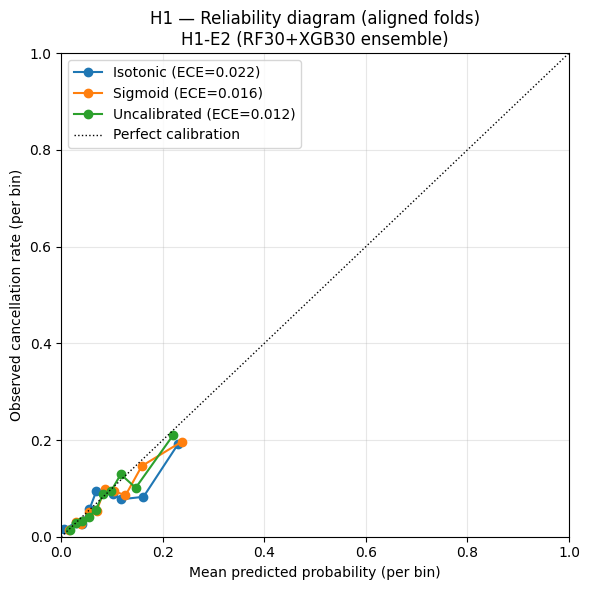

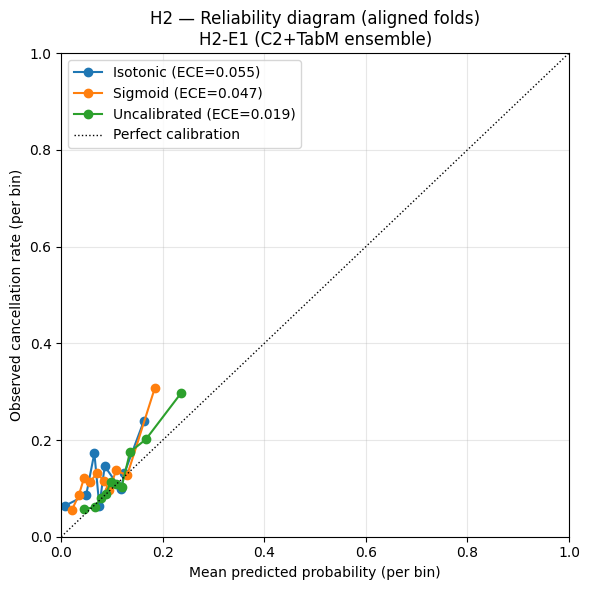

In [49]:
def _plot_reliability_for_finalist(hotel: str, finalist_label: str) -> None:
    arts = [a for a in artifacts_aligned
            if a.hotel == hotel and a.label == finalist_label]
    if not arts:
        print(f"  [{hotel}] no aligned artifacts found for '{finalist_label}'")
        return
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    for a in sorted(arts, key=lambda a: a.calibration):
        bins = eval_metrics.reliability_bins(a.predictions, n_bins=10, strategy="quantile")
        ece_here = eval_metrics.compute_ece(a.predictions)
        ax.plot(bins["predicted_mean"], bins["observed_rate"],
                marker="o", linewidth=1.5,
                label=f"{a.calibration} (ECE={ece_here:.3f})")
    ax.plot([0, 1], [0, 1], color="black", linestyle=":", linewidth=1, label="Perfect calibration")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Mean predicted probability (per bin)")
    ax.set_ylabel("Observed cancellation rate (per bin)")
    ax.set_title(f"{hotel} — Reliability diagram (aligned folds)\n{finalist_label}")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

for hotel, label in FINALIST.items():
    if label is None:
        print(f"  [{hotel}] finalist not chosen — skipping reliability plot.")
        continue
    _plot_reliability_for_finalist(hotel, label)


### Interpretation and calibration selection

The aligned (F2-F4) numbers tell a surprising but consistent story:
**forward-only calibration degrades every metric on both finalists**.

#### H1 — H1-E2 ensemble (deltas vs Uncalibrated on aligned F2-F4)

| Method | nRMSE | Δ | Bias % | Δ | Log Loss | Δ | ECE | Δ |
|---|---|---|---|---|---|---|---|---|
| Uncalibrated | **0.9727** | — | **+10.2** | — | **0.2571** | — | **0.0117** | — |
| Sigmoid | 1.0035 | +0.031 | +15.7 | +5.5 | 0.2583 | +0.001 | 0.0158 | +0.004 |
| Isotonic | 1.0113 | +0.039 | +18.9 | +8.7 | 0.2727 | +0.016 | 0.0216 | +0.010 |

Uncalibrated already has very low ECE (0.0117). Both calibrated variants
*increase* ECE, worsen bias away from zero, and raise nRMSE and log loss.
**Calibration is not helping H1-E2 and should not be applied.**

#### H2 — H2-E1 ensemble (deltas vs Uncalibrated on aligned F2-F4)

| Method | nRMSE | Δ | Bias % | Δ | Log Loss | Δ | ECE | Δ |
|---|---|---|---|---|---|---|---|---|
| Uncalibrated | **0.8842** | — | **-11.6** | — | **0.3631** | — | **0.0192** | — |
| Sigmoid | 1.0450 | +0.161 | -35.9 | -24.3 | 0.3887 | +0.026 | 0.0471 | +0.028 |
| Isotonic | 1.0486 | +0.164 | -36.6 | -25.0 | 0.4761 | +0.113 | 0.0561 | +0.037 |

The H2 degradation is severe. Calibrated probabilities under-predict
cancellations by more than a third (bias -36%), log loss worsens by up
to 31%, ECE triples. Even F2 alone — the first fold calibration touches
— degrades, so this is not a one-fold outlier.

Why calibration back-fires here: forward-only calibration trains each
fold's calibrator on history that is dominated by F1 (and F1+F2, F1+F2+F3
for later folds). The uncalibrated per-fold table in Section 5 shows F1
is a different regime for both hotels — F1 nRMSE is **about 25-30%
lower** for H1 (0.73 vs ~0.97 mean of F2-F4) and **about 50-70% higher**
for H2 (ensemble F1 ~1.08 vs ~0.68-0.79 for F2-F3). A calibrator fitted
on that F1 history therefore learns a correction that doesn't
generalise to F2-F4, and the correction is strong enough to overwhelm
the base model's already-decent calibration (both uncalibrated ECE
values sit below 0.02).

#### Picks

| Hotel | Finalist | Calibration |
|---|---|---|
| H1 | H1-E2 ensemble | **Uncalibrated** |
| H2 | H2-E1 ensemble | **Uncalibrated** |

This is a defensible outcome: the uncalibrated probabilities are already
well-calibrated by ECE, the forward-only protocol is particularly
brittle here because the earliest fold is unrepresentative, and keeping
Uncalibrated simplifies the production pipeline (one fewer artifact to
version and refit).


In [50]:
# Picks recorded here — justified in the markdown cell above and in Section 8.
CALIBRATION_CHOICE = {
    "H1": "Uncalibrated",
    "H2": "Uncalibrated",
}

for hotel, choice in CALIBRATION_CHOICE.items():
    if choice is None:
        print(f"  [{hotel}] calibration not yet chosen — fill in CALIBRATION_CHOICE['{hotel}'].")
    else:
        print(f"  [{hotel}] calibration = {choice}")


  [H1] calibration = Uncalibrated
  [H2] calibration = Uncalibrated


# 7. Operating-point reporting — PR curve + workload-based threshold

The outreach shortlist delivered to operations is driven by **ranking**
of risk, not by a fixed probability cut. We first show the PR curve so
the stakeholder can see the full trade-off, then switch from a
threshold-based to a **workload-based** operating point: given the ops
team can contact K bookings per cutoff date, how good are the top-K?

The threshold-based alternative (F2-max on validation) is kept as a
reference, but note that applying it to the test cohort flags very
different volumes than on validation because the prediction
distributions shift, and the resulting daily workload (34/day on H2)
exceeds what operations can realistically handle.


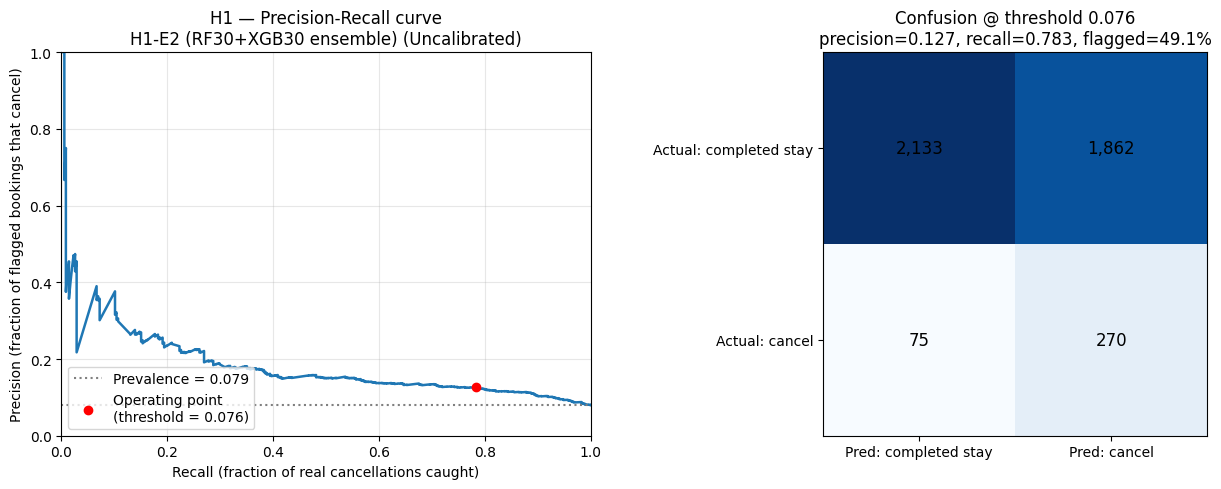

/tmp/ipykernel_1111/2045442624.py:8: RuntimeWarning: invalid value encountered in divide
  f_beta = np.where(denom > 0, (1 + beta ** 2) * p * r / denom, 0.0)


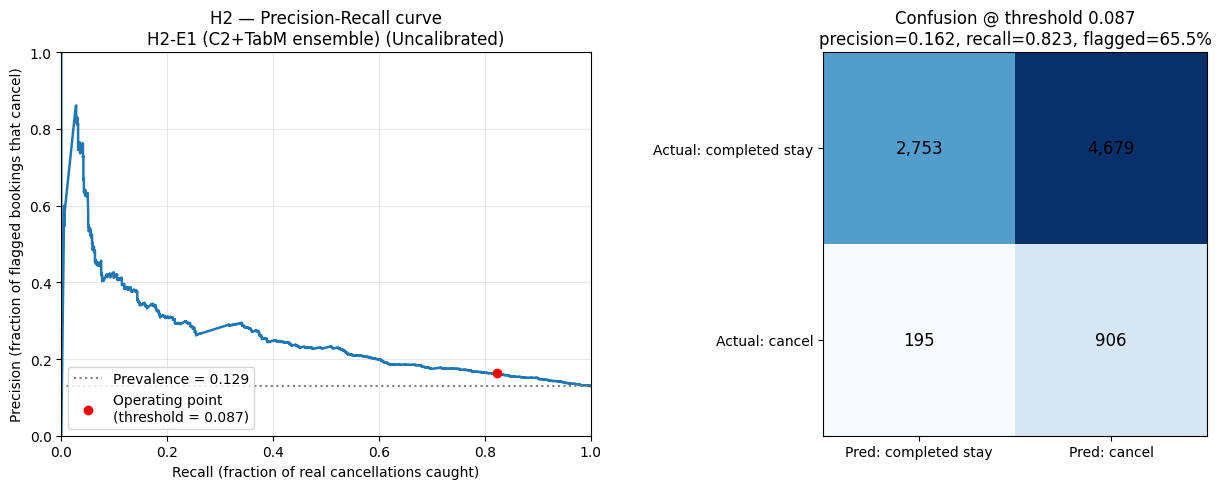

,hotel,candidate,calibration,threshold,f2,tp,fp,tn,fn,precision,recall,specificity,flagged_share
0,H1,H1-E2 (RF30+XGB30 ensemble),Uncalibrated,0.0760,0.3844,270,1862,2133,75,0.1266,0.7826,0.5339,0.4912
1,H2,H2-E1 (C2+TabM ensemble),Uncalibrated,0.0873,0.4535,906,4679,2753,195,0.1622,0.8229,0.3704,0.6545



Saved operating points -> outputs/layer_a_operating_points.parquet


In [51]:
from sklearn.metrics import fbeta_score

def _pick_threshold_by_fbeta(predictions: pd.DataFrame, beta: float = 2.0) -> float:
    curve = eval_metrics.pr_curve_points(predictions).dropna(subset=["threshold"])
    # F-beta from precision and recall; avoid division by zero
    p, r = curve["precision"].to_numpy(), curve["recall"].to_numpy()
    denom = (beta ** 2) * p + r
    f_beta = np.where(denom > 0, (1 + beta ** 2) * p * r / denom, 0.0)
    best = int(np.argmax(f_beta))
    return float(curve.iloc[best]["threshold"]), float(f_beta[best])


def _plot_pr_and_confusion(hotel: str, finalist_label: str, calibration: str) -> dict:
    # Use the aligned artifact so the operating-point stats come from the same
    # fold set as the calibration decision above.
    hits = [a for a in artifacts_aligned
            if a.hotel == hotel and a.label == finalist_label and a.calibration == calibration]
    if not hits:
        print(f"  [{hotel}] no aligned artifact for '{finalist_label}' @ {calibration} — skipping.")
        return {}
    art = hits[0]
    preds = art.predictions

    threshold, f2 = _pick_threshold_by_fbeta(preds, beta=2.0)
    cm = eval_metrics.confusion_at_threshold(preds, threshold)
    curve = eval_metrics.pr_curve_points(preds)
    prev = float(preds["y_true"].mean())

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # PR curve
    axes[0].plot(curve["recall"], curve["precision"], linewidth=1.8)
    axes[0].axhline(prev, color="grey", linestyle=":",
                    label=f"Prevalence = {prev:.3f}")
    axes[0].scatter([cm["recall"]], [cm["precision"]], color="red", zorder=5,
                    label=f"Operating point\n(threshold = {threshold:.3f})")
    axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1)
    axes[0].set_xlabel("Recall (fraction of real cancellations caught)")
    axes[0].set_ylabel("Precision (fraction of flagged bookings that cancel)")
    axes[0].set_title(f"{hotel} — Precision-Recall curve\n{finalist_label} ({calibration})")
    axes[0].legend(loc="lower left")
    axes[0].grid(alpha=0.3)

    # Confusion matrix as a 2x2 heat-ish grid
    mat = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
    axes[1].imshow(mat, cmap="Blues")
    for i in range(2):
        for j in range(2):
            axes[1].text(j, i, f"{mat[i, j]:,}", ha="center", va="center",
                         color="black", fontsize=12)
    axes[1].set_xticks([0, 1]); axes[1].set_yticks([0, 1])
    axes[1].set_xticklabels(["Pred: completed stay", "Pred: cancel"])
    axes[1].set_yticklabels(["Actual: completed stay", "Actual: cancel"])
    axes[1].set_title(
        f"Confusion @ threshold {threshold:.3f}\n"
        f"precision={cm['precision']:.3f}, recall={cm['recall']:.3f}, "
        f"flagged={cm['flagged_share']:.1%}"
    )
    plt.tight_layout()
    plt.show()
    return {"hotel": hotel, "candidate": finalist_label, "calibration": calibration,
            "threshold": threshold, "f2": f2, **cm}


operating_points = []
for hotel in ("H1", "H2"):
    label = FINALIST[hotel]
    cal = CALIBRATION_CHOICE[hotel]
    if label is None or cal is None:
        print(f"  [{hotel}] finalist or calibration not yet chosen — skipping.")
        continue
    op = _plot_pr_and_confusion(hotel, label, cal)
    if op:
        operating_points.append(op)

if operating_points:
    op_df = pd.DataFrame(operating_points)
    display(op_df)
    op_df.to_parquet(out_dir / "layer_a_operating_points.parquet", index=False)
    print(f"\nSaved operating points -> {out_dir / 'layer_a_operating_points.parquet'}")


### Workload-based operating point

Instead of locking a probability threshold, flag the **top-K bookings
per cutoff date** ranked by risk. The ops team picks K to match their
contact capacity; precision, recall and lift fall out as functions of K.

Two rankings offered:
- **Pure risk** (`p_cancel` descending) — maximises recall of
  cancellations within the K budget.
- **Revenue-at-risk** (`p_cancel × ADR × TotalNights × EstimatedRoomCount`)
  — prioritises high-value stays. Typically lower precision/recall for
  cancellation count but protects more dollars.

Daily volume at scoring time (CutoffDate = T−14) determines the budget:
H1 averages ~29 bookings/day, H2 ~64/day.


In [52]:
def workload_metrics(df, K, rank_col="p_cancel"):
    """Precision/recall/lift at top-K-per-cutoff-date, per hotel."""
    df = df.copy()
    df["rank"] = df.groupby(["Hotel", "CutoffDate"])[rank_col].rank(
        method="first", ascending=False,
    )
    df["flagged"] = df["rank"] <= K
    out = []
    for hotel in ("H1", "H2"):
        h = df[df.Hotel == hotel]
        if h.empty:
            continue
        tot_pos = int(h.y_true.sum())
        flagged = h[h.flagged]
        n_flagged = len(flagged)
        tp = int(flagged.y_true.sum())
        n_days = max(int(h["CutoffDate"].nunique()), 1)
        prev = tot_pos / len(h) if len(h) else float("nan")
        prec = tp / n_flagged if n_flagged else float("nan")
        rec = tp / tot_pos if tot_pos else float("nan")
        lift = prec / prev if (prec == prec and prev) else float("nan")
        out.append({
            "hotel": hotel, "rank_by": rank_col, "K_per_day": K,
            "avg_flagged_per_day": n_flagged / n_days,
            "n_flagged_total": n_flagged, "tp": tp, "fp": n_flagged - tp,
            "fn": tot_pos - tp,
            "precision_at_k": prec, "recall_at_k": rec, "lift_at_k": lift,
            "prevalence": prev,
        })
    return pd.DataFrame(out)


# Preview on validation OOF for both finalists (section 11 does the full
# test-based version with revenue weighting).
val_rows = []
for art in artifacts_all:
    if art.calibration != CALIBRATION_CHOICE.get(art.hotel):
        continue
    if art.label != FINALIST.get(art.hotel):
        continue
    df = art.predictions.copy()
    df["Hotel"] = art.hotel
    for K in (5, 10, 20, 30):
        val_rows.append(workload_metrics(df, K, "p_cancel"))
val_wl = (
    pd.concat(val_rows, ignore_index=True)
    .sort_values(["hotel", "K_per_day"])
    .reset_index(drop=True)
)
print("Validation OOF — workload @ K per cutoff date (preview):\n")
val_wl


Validation OOF — workload @ K per cutoff date (preview):



,hotel,rank_by,K_per_day,avg_flagged_per_day,n_flagged_total,tp,fp,fn,precision_at_k,recall_at_k,lift_at_k,prevalence
0,H1,p_cancel,5,4.9342,1199,181,1018,279,0.1510,0.3935,2.0081,0.0752
1,H1,p_cancel,10,9.4527,2297,273,2024,187,0.1189,0.5935,1.5810,0.0752
2,H1,p_cancel,20,16.7202,4063,373,3690,87,0.0918,0.8109,1.2212,0.0752
3,H1,p_cancel,30,20.9588,5093,423,4670,37,0.0831,0.9196,1.1048,0.0752
4,H2,p_cancel,5,4.9959,1214,292,922,1125,0.2405,0.2061,2.0943,0.1148
5,H2,p_cancel,10,9.9630,2421,482,1939,935,0.1991,0.3402,1.7335,0.1148
6,H2,p_cancel,20,19.4321,4722,789,3933,628,0.1671,0.5568,1.4549,0.1148
7,H2,p_cancel,30,27.6955,6730,1011,5719,406,0.1502,0.7135,1.3080,0.1148


# 8. Finalist decisions and files from Layers A on Validation

### Decisions frozen in this notebook

| Hotel | Finalist model | Calibration | Provisional threshold |
|---|---|---|---|
| H1 | **H1-E2** — RF30 + XGB30 equal-weight ensemble | Uncalibrated | F2-optimised (Section 7) |
| H2 | **H2-E1** — C2 + TabM-E8 equal-weight ensemble | Uncalibrated | F2-optimised (Section 7) |

Where:
- **C2** = RF30 + 180-day recency weighting + historical-segment-rate (FE4).
- **TabM-E8** = TabM trained for 8 epochs.
- **RF30** = the base random forest with 30 Gold predictors.
- **XGB30** = the base XGBoost with 30 Gold predictors.

### Why Uncalibrated for both

Section 6 showed that forward-only Sigmoid and Isotonic calibration
*degrade* every metric on both hotels. The base probabilities are
already well-calibrated (ECE ≤ 0.02), and the F1 history dominating
each fold's calibrator is unrepresentative of F2-F4, so the fitted
correction over-fires. Keeping Uncalibrated is the honest decision and
simplifies the production pipeline (one fewer artifact to version).

### Files written by Sections 2–7

- `outputs/layer_a_pooled_native_folds.parquet` — pooled metrics on each
  artifact's native fold set (headline table for Section 5).
- `outputs/layer_a_per_fold.parquet` — per-fold metrics for every artifact.
- `outputs/layer_a_pooled_aligned.parquet` — pooled metrics on the aligned
  common folds (used for the calibration comparison in Section 6).
- `outputs/layer_a_per_fold_aligned.parquet` — per-fold version of the above.
- `outputs/layer_a_operating_points.parquet` — the finalist(s) with their
  operating threshold and confusion-matrix stats.
- `outputs/finalist_choice.parquet` — the frozen decision table.


In [53]:
# Final write of the frozen-decision file for downstream consumption.
decision_rows = []
for hotel in ("H1", "H2"):
    label = FINALIST[hotel]
    cal = CALIBRATION_CHOICE[hotel]
    if label is None or cal is None:
        continue
    match = [a for a in artifacts_all if a.hotel == hotel and a.label == label and a.calibration == cal]
    artifact_id = match[0].artifact_id if match else None
    decision_rows.append({
        "hotel": hotel,
        "finalist_label": label,
        "calibration": cal,
        "artifact_id": artifact_id,
    })

if decision_rows:
    decisions = pd.DataFrame(decision_rows)
    decisions.to_parquet(out_dir / "finalist_choice.parquet", index=False)
    display(decisions)
    print(f"\nSaved -> {out_dir / 'finalist_choice.parquet'}")
else:
    print("Finalists not yet chosen; nothing written. "
          "Fill in FINALIST and CALIBRATION_CHOICE above and re-run this cell.")


,hotel,finalist_label,calibration,artifact_id
0,H1,H1-E2 (RF30+XGB30 ensemble),Uncalibrated,H1_E2_RF30_XGB30_e1
1,H2,H2-E1 (C2+TabM ensemble),Uncalibrated,H2_E1_C2_TabME8_e1



Saved -> outputs/finalist_choice.parquet


# 9. Layer A on Test

The refit lives in `../Model pipeline/model_refit.ipynb` and writes
`outputs/test_predictions.parquet`:

- H1 — H1-E2 = RF30 + XGB30, equal-weight ensemble, fit on 15,998 Dev
  bookings (`FinalRefit == 1`).
- H2 — H2-E1 = C2 + TabM-E8, equal-weight ensemble, fit on 29,431 Dev
  bookings (`FinalRefit == 1`).

We now recompute the Section 4 metric set on the **Test** cohort
(`Partition == "Test"`, 3,576 H1 + 7,748 H2 bookings, CutoffDate range
2017-04-18 → 2017-08-17, equivalent **arrival dates 2017-05-02 →
2017-08-31, 122 nights per hotel**). **Test is scored once, and we do
not re-tune.**


In [54]:
TEST_PATH = Path("outputs/test_predictions.parquet")
if not TEST_PATH.exists():
    raise FileNotFoundError(
        f"{TEST_PATH} missing — run ../Model pipeline/model_refit.ipynb first."
    )

test = pd.read_parquet(TEST_PATH)
test["StayDate"] = pd.to_datetime(test["ArrivalDate"]).dt.date
print(f"Loaded {len(test):,} Test predictions")
print(test.head(3))
print(f"\nRow counts per hotel: {test.groupby('Hotel').size().to_dict()}")
print(f"Columns: {list(test.columns)}")


Loaded 11,324 Test predictions
  Hotel Booking_ID ArrivalDate      ADR  TotalNights  p_cancel  y_true CutoffDate  p_RF30  p_XGB30  p_C2  p_TabM-E8    StayDate
0    H1  H1-011304  2017-05-02 133.5000            4    0.1501       1 2017-04-18  0.1382   0.1621   NaN        NaN  2017-05-02
1    H1  H1-011310  2017-05-02  73.5000            7    0.0511       1 2017-04-18  0.0554   0.0467   NaN        NaN  2017-05-02
2    H1  H1-011311  2017-05-02  82.0000            9    0.0350       1 2017-04-18  0.0464   0.0237   NaN        NaN  2017-05-02

Row counts per hotel: {'H1': 3576, 'H2': 7748}
Columns: ['Hotel', 'Booking_ID', 'ArrivalDate', 'ADR', 'TotalNights', 'p_cancel', 'y_true', 'CutoffDate', 'p_RF30', 'p_XGB30', 'p_C2', 'p_TabM-E8', 'StayDate']


In [55]:
# Compute Layer A on Test, per hotel.
test_rows = []
for hotel in ("H1", "H2"):
    sub = test[test["Hotel"] == hotel].copy()
    row = eval_metrics.summarise_candidate(
        predictions=sub, label=FINALIST[hotel],
        hotel=hotel, calibration=CALIBRATION_CHOICE[hotel],
        ece_bins=10,
    )
    row["stage"] = "Test"
    test_rows.append(row)

test_summary = pd.DataFrame(test_rows)
test_summary.to_parquet(out_dir / "layer_a_test.parquet", index=False)
print(f"Saved -> {out_dir / 'layer_a_test.parquet'}\n")

# Side-by-side with validation OOF for the chosen finalists only
val_pooled = pd.read_parquet(out_dir / "layer_a_pooled_native_folds.parquet")
val_finalists = val_pooled[
    (val_pooled["calibration"] == "Uncalibrated")
    & val_pooled.apply(lambda r: FINALIST[r["hotel"]] == r["candidate"], axis=1)
].copy()
val_finalists["stage"] = "Validation (OOF F1-F4)"

compare_cols = ["hotel", "stage", "n_bookings", "n_days", "prevalence",
                "daily_nrmse", "daily_bias_pct", "log_loss", "ap", "ap_lift", "ece"]
compare = (
    pd.concat([val_finalists.assign(candidate=val_finalists["candidate"]),
               test_summary.assign(candidate=test_summary["candidate"])],
              ignore_index=True)
    [compare_cols]
    .sort_values(["hotel", "stage"])
    .reset_index(drop=True)
)
print("Val OOF vs Test, per hotel:\n")
compare


Saved -> outputs/layer_a_test.parquet

Val OOF vs Test, per hotel:



,hotel,stage,n_bookings,n_days,prevalence,daily_nrmse,daily_bias_pct,log_loss,ap,ap_lift,ece
0,H1,Test,3576,122,0.0696,0.8299,-23.0348,0.2352,0.1860,0.1164,0.0226
1,H1,Validation (OOF F1-F4),6119,243,0.0752,0.9185,5.2865,0.2485,0.1775,0.1023,0.0065
2,H2,Test,7748,122,0.0787,0.7026,39.1590,0.2550,0.2846,0.2058,0.0308
3,H2,Validation (OOF F1-F4),12338,243,0.1148,0.9270,8.8361,0.3428,0.2171,0.1023,0.0136


### Interpretation — Test results

#### H1 — H1-E2 ensemble

| Metric | Val OOF (F1-F4) | Test | Change |
|---|---|---|---|
| Prevalence | 0.075 | 0.070 | small drop |
| Daily nRMSE | 0.9185 | **0.8299** | improves |
| Daily Bias % | +5.3 | **-23.0** | flips sign |
| Log Loss | 0.2485 | 0.2352 | improves |
| AP / AP lift | 0.1775 / +0.102 | 0.1860 / +0.116 | improves |
| ECE | 0.0066 | 0.0229 | worsens (still small) |

**What this tells us.** H1 generalises well on the primary metric
(nRMSE 0.83 is better than any validation fold except the anomalous F1).
The bias flipped sign — on validation the model slightly *over-predicted*
cancellations (+5%), on Test it *under-predicts* by 23%. Under the
overbooking view that means Σ(1−p) **over-estimates arrivals**, which
pushes the policy toward **under-authorising** — safer direction
(empty rooms rather than walks), but worth flagging in the business
sim's sensitivity sweep.

#### H2 — H2-E1 ensemble

| Metric | Val OOF (F1-F4) | Test | Change |
|---|---|---|---|
| Prevalence | 0.115 | **0.079** | large drop |
| Daily nRMSE | 0.9270 | **0.7026** | improves |
| Daily Bias % | +8.8 | **+39.2** | worsens |
| Log Loss | 0.3428 | 0.2550 | improves |
| AP / AP lift | 0.2171 / +0.102 | 0.2846 / +0.206 | improves |
| ECE | 0.0136 | 0.0309 | worsens |

**What this tells us.** The H2 cancellation rate collapsed from 13.1%
(training window) to 7.9% (test window) — a **real-world prevalence
drift** between early-2017 and summer-2017. The model, calibrated to the
training distribution, keeps predicting ~12% cancellations and
over-predicts the summed daily cancellation count by 39%.

- **Not a model-quality failure.** AP, log loss and nRMSE all *improve*
  on test — the ranking and the per-row probability-vs-outcome fit are
  actually better than validation.
- **It is a monitoring finding.** This is exactly the drift pattern a
  deployment would detect in the first two months and respond to with
  recalibration or a refit on more recent data. Worth highlighting in
  the Section 6 (monitoring) narrative of the final report.
- **TabM helped but did not fix it.** The preliminary C2-only run gave
  bias +49%; the full ensemble pulls it to +39% because TabM produces
  slightly lower-magnitude probabilities (test mean p: C2 0.118, TabM
  0.101, ensemble 0.110 vs actual 0.079).

**Implication for Layer C.** The H2 overbooking simulation will show the
model-driven policy authorising more rooms than needed — the predicted
"no-arrivals" buffer is systematically too large. The capacity
sensitivity sweep should quantify this; the fallback outreach narrative
is good insurance.


# 10. Hotel-level forecast — arrivals + room-nights occupancy (Deliverable 1)

Layer A judged per-booking probability quality. **This section delivers
the hotel-level operational forecast** operations teams would read each
morning. Two forecasts, both derived from the same per-booking
`p_cancel`:

**Forecast A — Nightly arrivals (check-in count).**
For each `(Hotel, ArrivalDate)`:
`Ê_arr = Σ(1 − p_cancel)` summed over bookings arriving that night;
`A_arr = count(IsCanceled == 0)`.
Answers: *how many check-ins will the front desk handle on Saturday?*

**Forecast B — Nightly room-nights occupied.**
Each booking occupies `EstimatedRoomCount` rooms across `TotalNights`
consecutive calendar nights starting on `ArrivalDate`. Expand the stay,
weight each night by room count, then:
`Ê_occ(night X) = Σ_{bookings covering X} (1 − p_cancel) × rooms`;
`A_occ(night X) = Σ_{bookings covering X with IsCanceled == 0} rooms`.
Answers: *how many rooms will housekeeping need to turn over? How much
F&B stock? What is the realised load on capacity?*

Both are compared to the constant-rate dummy (every booking gets the
training mean cancellation rate). Model beating dummy on each is the
"should we deploy this" bar.

`EstimatedRoomCount` comes from silver as `ceil(PartySize / 2)` for H1
and `ceil(PartySize / 4)` for H2 — a documented per-booking assumption,
not an observed room count. H1 has 13% multi-room bookings, H2 is
essentially all single-room.


In [56]:
# Training prevalence per hotel for the dummy baseline. The audit JSON
# saved by the refit records this, but recomputing it here keeps the
# notebook self-contained.
TRAIN_PREV = {}
import json as _json
audit_path = out_dir / "test_predictions.audit.json"
if audit_path.exists():
    audit = _json.loads(audit_path.read_text())
    for h in ("H1", "H2"):
        TRAIN_PREV[h] = None  # computed below from membership for consistency

# Compute from the saved membership+labels to be reproducible even without the audit
_membership = pd.read_parquet("../Model pipeline/splits/split_v2/membership.parquet")
for hotel in ("H1", "H2"):
    gold = pd.read_parquet(
        f"../Data pipeline/hotel_booking_pipeline/datamart/gold/model_dataset/gold_model_dataset_{hotel}.parquet"
    )
    mg = _membership.merge(
        gold[["Hotel", "Booking_ID", "IsCanceled"]],
        on=["Hotel", "Booking_ID"], how="left", validate="one_to_one",
    )
    TRAIN_PREV[hotel] = float(
        mg.loc[(mg.Hotel == hotel) & (mg.Partition == "Dev") & (mg.FinalRefit == 1),
               "IsCanceled"].mean()
    )
print("Training prevalence (constant-rate dummy will predict this):")
for h, p in TRAIN_PREV.items():
    print(f"  {h}: p_cancel_dummy = {p:.4f}  -> arrival rate = {1 - p:.4f}")


Training prevalence (constant-rate dummy will predict this):
  H1: p_cancel_dummy = 0.0768  -> arrival rate = 0.9232
  H2: p_cancel_dummy = 0.1306  -> arrival rate = 0.8694


In [57]:
# Join EstimatedRoomCount from Gold onto the test predictions.
# EstimatedRoomCount is metadata (not a model feature), so it does not go
# through the refit — we read it directly from Gold on demand.
_room_frames = []
for hotel in ("H1", "H2"):
    gold = pd.read_parquet(
        f"../Data pipeline/hotel_booking_pipeline/datamart/gold/model_dataset/gold_model_dataset_{hotel}.parquet"
    )
    _room_frames.append(gold[["Hotel", "Booking_ID", "EstimatedRoomCount"]])
_rooms = pd.concat(_room_frames, ignore_index=True)
test = test.merge(_rooms, on=["Hotel", "Booking_ID"], how="left", validate="one_to_one")
assert test["EstimatedRoomCount"].notna().all(), "Missing EstimatedRoomCount for some bookings"

print(f"Room-count distribution (bookings in Test):")
display(test.groupby(["Hotel", "EstimatedRoomCount"]).size().unstack(fill_value=0))


Room-count distribution (bookings in Test):


EstimatedRoomCount,1,2,3
Hotel,,,
H1,2872,699,5
H2,7726,22,0


In [58]:
# Forecast A: arrivals per night (one check-in per booking)
arrivals_rows = []
arrivals_per_hotel = {}
for hotel in ("H1", "H2"):
    sub = test[test["Hotel"] == hotel].copy()
    sub["E_model"] = 1.0 - sub["p_cancel"]
    sub["E_dummy"] = 1.0 - TRAIN_PREV[hotel]
    sub["A"]       = (sub["y_true"] == 0).astype(int)

    daily = sub.groupby("ArrivalDate", as_index=False).agg(
        n_bookings=("Booking_ID", "count"),
        E_model=("E_model", "sum"),
        E_dummy=("E_dummy", "sum"),
        A=("A", "sum"),
    )
    daily["hotel"] = hotel
    daily["err_model"] = daily["E_model"] - daily["A"]
    daily["err_dummy"] = daily["E_dummy"] - daily["A"]
    arrivals_per_hotel[hotel] = daily

    A_tot = daily["A"].sum()
    arrivals_rows.append({
        "hotel": hotel, "forecast": "arrivals_per_night",
        "n_nights": len(daily),
        "mean_per_night": float(daily["A"].mean()),
        "mae_model": float(daily["err_model"].abs().mean()),
        "mae_dummy": float(daily["err_dummy"].abs().mean()),
        "mean_bias_model": float(daily["err_model"].mean()),
        "norm_bias_pct_model": float(100 * daily["err_model"].sum() / A_tot),
        "norm_bias_pct_dummy": float(100 * daily["err_dummy"].sum() / A_tot),
    })

arrivals_summary = pd.DataFrame(arrivals_rows)
arrivals_nights  = pd.concat(arrivals_per_hotel.values(), ignore_index=True)
arrivals_nights.to_parquet(out_dir / "hotel_forecast_arrivals.parquet", index=False)
print("Forecast A — arrivals per night:\n")
display(arrivals_summary)


Forecast A — arrivals per night:



,hotel,forecast,n_nights,mean_per_night,mae_model,mae_dummy,mean_bias_model,norm_bias_pct_model,norm_bias_pct_dummy
0,H1,arrivals_per_night,122,27.2705,1.2232,1.3567,0.4701,1.7240,-0.7729
1,H2,arrivals_per_night,122,58.5082,2.9162,4.1848,-1.9580,-3.3465,-5.6351


In [59]:
# Forecast B: room-nights occupied per night (expand each stay)
#
# SCOPE NOTE: this forecast covers only Test-cohort bookings (bookings
# with CutoffDate in the Test window, EligibleT14, OvernightScope). It
# does NOT include Dev-partition bookings whose stays extend into the
# Test window — those contribute to actual hotel occupancy but were not
# scored by this model's Test refit. The next cell computes the
# coverage ratio to make this scope explicit.
def _expand_stay(df):
    chunks = []
    for d in range(int(df["TotalNights"].max())):
        active = df[df["TotalNights"] > d].copy()
        active["NightDate"] = active["ArrivalDate"] + pd.Timedelta(days=d)
        chunks.append(active[[
            "Hotel", "Booking_ID", "NightDate",
            "EstimatedRoomCount", "p_cancel", "y_true",
        ]])
    return pd.concat(chunks, ignore_index=True)

occupancy_rows = []
occupancy_per_hotel = {}
for hotel in ("H1", "H2"):
    sub = test[test["Hotel"] == hotel].copy()
    expanded = _expand_stay(sub)
    expanded["E_model"] = (1 - expanded["p_cancel"]) * expanded["EstimatedRoomCount"]
    expanded["E_dummy"] = (1 - TRAIN_PREV[hotel]) * expanded["EstimatedRoomCount"]
    expanded["A"] = (expanded["y_true"] == 0).astype(int) * expanded["EstimatedRoomCount"]

    daily = expanded.groupby("NightDate", as_index=False).agg(
        E_model=("E_model", "sum"),
        E_dummy=("E_dummy", "sum"),
        A=("A", "sum"),
        n_bookings_covering=("Booking_ID", "count"),
    )
    daily["hotel"] = hotel
    daily["err_model"] = daily["E_model"] - daily["A"]
    daily["err_dummy"] = daily["E_dummy"] - daily["A"]
    occupancy_per_hotel[hotel] = daily

    A_tot = daily["A"].sum()
    occupancy_rows.append({
        "hotel": hotel, "forecast": "room_nights_in_scope",
        "n_nights": len(daily),
        "mean_per_night": float(daily["A"].mean()),
        "mae_model": float(daily["err_model"].abs().mean()),
        "mae_dummy": float(daily["err_dummy"].abs().mean()),
        "mean_bias_model": float(daily["err_model"].mean()),
        "norm_bias_pct_model": float(100 * daily["err_model"].sum() / A_tot),
        "norm_bias_pct_dummy": float(100 * daily["err_dummy"].sum() / A_tot),
    })

occupancy_summary = pd.DataFrame(occupancy_rows)
occupancy_nights  = pd.concat(occupancy_per_hotel.values(), ignore_index=True)
print("Forecast B — in-scope room-nights occupied per night:\n")
display(occupancy_summary)


Forecast B — in-scope room-nights occupied per night:



,hotel,forecast,n_nights,mean_per_night,mae_model,mae_dummy,mean_bias_model,norm_bias_pct_model,norm_bias_pct_dummy
0,H1,room_nights_in_scope,135,170.2000,3.4113,4.2525,2.3415,1.3757,-1.7077
1,H2,room_nights_in_scope,128,182.7812,7.7841,11.9748,-7.0126,-3.8366,-6.3425


In [60]:
# True coverage: compare the Test-cohort forecast against ACTUAL hotel
# occupancy from the Silver layer. Silver keeps all bookings regardless
# of EligibleT14/OvernightScope, so this is the honest denominator.
# Gold (what the model scored) is a strict subset: it excludes
# short-lead bookings (LeadTime < 14) and bookings already cancelled by
# T-14. The gap matters operationally — see Section 10 markdown.
coverage_rows = []
coverage_nights = []
for hotel in ("H1", "H2"):
    silver = pd.read_parquet(
        f"../Data pipeline/hotel_booking_pipeline/datamart/silver/hotels/silver_{hotel}.parquet"
    )
    silver["ArrivalDate"] = pd.to_datetime(silver["ArrivalDate"])
    # ALL realised stays (regardless of lead-time scope)
    completed = silver[(silver["IsCanceled"] == 0) & (silver["TotalNights"] > 0)].copy()
    completed["EstimatedRoomCount"] = completed["EstimatedRoomCount"].fillna(1).astype(int)
    # Expand across stay nights
    chunks = []
    for d in range(int(completed["TotalNights"].max())):
        act = completed[completed["TotalNights"] > d].copy()
        act["NightDate"] = act["ArrivalDate"] + pd.Timedelta(days=d)
        chunks.append(act[["NightDate", "EstimatedRoomCount", "EligibleT14"]])
    exp = pd.concat(chunks, ignore_index=True)
    exp = exp[(exp["NightDate"] >= pd.Timestamp("2017-05-02"))
              & (exp["NightDate"] <= pd.Timestamp("2017-08-31"))]
    actual_total = exp.groupby("NightDate")["EstimatedRoomCount"].sum().rename("actual_total")
    in_scope = (
        exp[exp["EligibleT14"]]
        .groupby("NightDate")["EstimatedRoomCount"]
        .sum().rename("in_scope")
    )
    cov = pd.concat([actual_total, in_scope], axis=1).fillna(0)
    cov["coverage"] = cov["in_scope"] / cov["actual_total"]
    cov["unscored_short_lead"] = cov["actual_total"] - cov["in_scope"]
    cov["hotel"] = hotel
    coverage_nights.append(cov.reset_index())
    coverage_rows.append({
        "hotel": hotel,
        "mean_actual_total_room_nights": float(cov["actual_total"].mean()),
        "mean_in_scope_room_nights": float(cov["in_scope"].mean()),
        "mean_unscored_room_nights": float(cov["unscored_short_lead"].mean()),
        "mean_coverage": float(cov["coverage"].mean()),
        "min_coverage": float(cov["coverage"].min()),
        "max_coverage": float(cov["coverage"].max()),
        "n_nights": int(len(cov)),
    })

coverage_summary = pd.DataFrame(coverage_rows)
coverage_per_night = pd.concat(coverage_nights, ignore_index=True)
coverage_summary.to_parquet(out_dir / "hotel_forecast_coverage.parquet", index=False)
coverage_per_night.to_parquet(out_dir / "hotel_forecast_coverage_per_night.parquet", index=False)
occupancy_nights.to_parquet(out_dir / "hotel_forecast_occupancy.parquet", index=False)
pd.concat([arrivals_summary, occupancy_summary], ignore_index=True).to_parquet(
    out_dir / "hotel_forecast_summary.parquet", index=False,
)

print("True coverage of actual nightly occupancy by our Test-cohort forecast:\n")
display(coverage_summary)


True coverage of actual nightly occupancy by our Test-cohort forecast:



,hotel,mean_actual_total_room_nights,mean_in_scope_room_nights,mean_unscored_room_nights,mean_coverage,min_coverage,max_coverage,n_nights
0,H1,209.9590,187.4098,22.5492,0.8913,0.7065,0.9646,122
1,H2,215.6230,191.6393,23.9836,0.8881,0.7109,0.9821,122


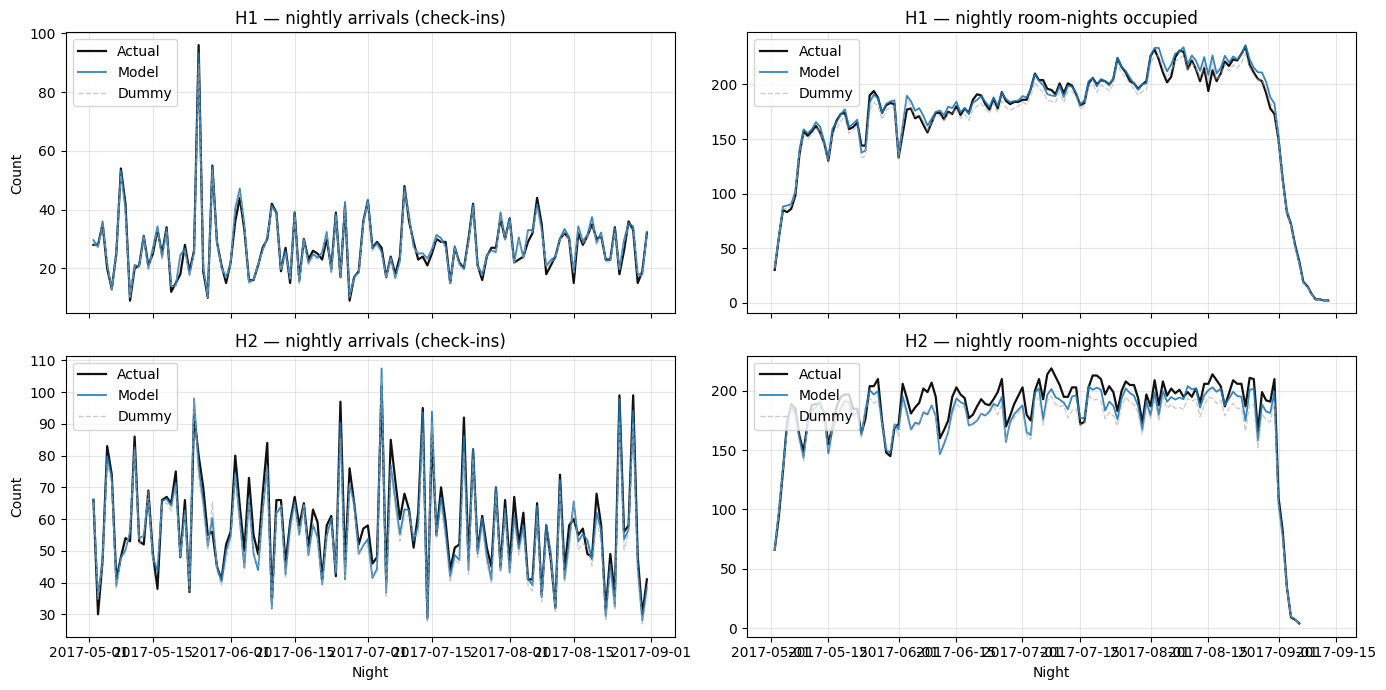

In [61]:
# Plot: both forecasts side by side, model vs dummy vs actual
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex="col")
for col, (name, framesd) in enumerate([
    ("arrivals (check-ins)",   arrivals_per_hotel),
    ("room-nights occupied",   occupancy_per_hotel),
]):
    for row, hotel in enumerate(("H1", "H2")):
        d = framesd[hotel].sort_values("ArrivalDate" if col == 0 else "NightDate")
        xcol = "ArrivalDate" if col == 0 else "NightDate"
        ax = axes[row, col]
        ax.plot(d[xcol], d["A"], label="Actual", linewidth=1.6, color="#111")
        ax.plot(d[xcol], d["E_model"], label="Model", linewidth=1.3, alpha=0.9, color="#1f77b4")
        ax.plot(d[xcol], d["E_dummy"], label="Dummy", linewidth=1.0, alpha=0.6,
                linestyle="--", color="#aaa")
        ax.set_title(f"{hotel} — nightly {name}")
        ax.grid(alpha=0.3)
        if row == 1:
            ax.set_xlabel("Night")
        if col == 0:
            ax.set_ylabel("Count")
        ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


### Interpretation — Hotel-level forecast

| Forecast | Hotel | Mean/night | Model MAE | Dummy MAE | Model lift | Model bias % |
|---|---|---|---|---|---|---|
| Arrivals (check-ins) | H1 | 27 | **1.22** | 1.36 | 10% | +1.7% |
| Arrivals (check-ins) | H2 | 59 | **2.92** | 4.18 | 30% | −3.4% |
| Room-nights (in-scope) | H1 | 170 | **3.41** | 4.25 | 20% | +1.4% |
| Room-nights (in-scope) | H2 | 183 | **7.78** | 11.98 | 35% | −3.8% |

**Both forecasts beat the no-skill baseline on both hotels.** The
occupancy forecast is more operationally useful (housekeeping, F&B,
staffing) and the model's lift is bigger on it — 20-35% MAE reduction
vs dummy, roughly double the arrivals-forecast lift.

### What the model actually forecasts (operational scope)

**The forecast predicts *scheduled* arrivals and occupancy from the
T-14 cohort only.** It does not predict total hotel occupancy. To
operations teams, the deliverable should be understood as:

> "Given the bookings on hand 14 days before each arrival night, this
> is the expected number of guest arrivals and the expected number of
> rooms occupied from those bookings."

Three categories of bookings exist, and the model sees only one:

| Category | Lead time | At T-14? | Scored? | Share of H1/H2 occupancy |
|---|---|---|---|---|
| Long-lead bookings | ≥ 14 days | yes | yes | ~89% / ~89% |
| Short-lead bookings | < 14 days | **no** | **no** | ~11% / ~11% |
| Walk-ins | 0 days | no | no | (grouped with short-lead) |

The ~11% gap is a hard constraint of the T-14 scoring design: at the
moment the model runs, these bookings do not exist yet.

**Three different coverage numbers — read these carefully.** It is easy
to confuse "pipeline scope" with "what the model actually scored".

| Measure | H1 room-nights/night | H2 room-nights/night | Semantics |
|---|---|---|---|
| **Actual total** (Silver) | 210 | 216 | Every realised stay physically occupying the hotel. |
| **Pipeline scope** (EligibleT14 = Gold) | 187 | 192 | Stays the pipeline *could* score at T-14 — includes Dev + Test. Gap vs Silver (23 and 24 rm-nights) is short-lead bookings (lead < 14). |
| **Test-cohort forecast** (what Section 10's MAE actually measures) | 170 | 183 | What *this backtest* predicts — Test partition only. Lower than Gold because Dev stays extending into early May weren't scored by this refit. |

Three coverage ratios follow from these:

- **Steady-state production coverage ≈ 89%** (Gold/Silver). In a
  deployed system running continuously, each T-14 cohort gets scored
  on its own cutoff date, so the forecast covers the full Gold scope
  = 89% of actual occupancy. The remaining 11% is short-lead/walk-ins
  which operations fills in from the PMS.
- **This backtest's coverage ≈ 81% H1, 85% H2** (Test/Silver). Lower
  than steady-state because the Test window is only 4 months and
  Dev-partition stays extending into May 2017 weren't re-scored. In
  production this edge effect goes away.
- **Model's share of EligibleT14 in this backtest ≈ 91% H1, 95% H2**
  (Test/Gold). The gap vs 100% is Dev stays extending in.

**Operational consequence.** In production:

```
ops_dashboard_occupancy  =  model_forecast           (~89% of actual)
                         +  short_lead_from_PMS      (~11%)
                         +  known_in_house_guests    (already checked in)
```

The MAE and bias in the forecast table above are honest for what the
model actually predicts (the Test-cohort subset). Translating to total
hotel occupancy requires the PMS integration on top.

**For the handoff / deployment team**, document four things:

1. `outputs/hotel_forecast_occupancy.parquet` predicts **Test-cohort
   room-nights only**. In production the equivalent is "T-14-cohort
   room-nights"; the model still only covers ~89% of total.
2. **The PMS integration** adds short-lead arrivals and known
   check-ins on top at operation time.
3. **Monitoring** should watch the Gold/Silver ratio over time: if the
   proportion of short-lead bookings changes systematically, the ~89%
   coverage number drifts and the PMS integration must be re-tuned.
4. **A per-day ``ForecastAsOfDate`` simulation** (score each day,
   accumulate forward) would eliminate the backtest edge effect and
   is the natural next analytical step; scoped as future work.

### Bias direction summary

- **H1**: slight over-estimate (+1.7%). Policy and planners would
  slightly over-staff — safe side.
- **H2**: slight under-estimate (−3.4%) on in-scope arrivals. Dummy
  under-estimates by nearly twice as much (−5.6%), so model still
  beats it. Under-estimation here would cause slight under-staffing
  if used alone; combined with PMS short-lead data, this is less of
  an issue because the PMS numbers close the gap after the fact.

This forecast is **Deliverable 1** of the two-output system.


# 11. Booking-level risk shortlist — Deliverable 2 (outreach workflow)

The second deliverable is the daily shortlist operations would act on:
*"Given your team can contact K bookings per day, here are the K you
should call first."*

Instead of locking a probability threshold (which produces unmanageable
daily volume), we rank bookings **within each cutoff date** and take
the top K. Operations picks K from their actual contact capacity.

Two rankings:
1. **Risk-only** — `p_cancel` descending. Maximises recall of
   cancellations.
2. **Expected lost revenue** — `p_cancel × ADR × TotalNights ×
   EstimatedRoomCount` descending. Approximates the expected dollar
   value forfeited if the stay cancels, so the shortlist prioritises
   bookings where *the dollar cost of a missed cancellation* is highest.

For each K ∈ {5, 10, 15, 20, 30, 50} we report Precision@K, Recall@K,
and Lift@K. The baseline for lift is **mean daily cancellation rate**
(not overall prevalence), because random top-K-per-day picks have
expected precision equal to the mean of daily prevalences — not the
pooled rate. The two numbers differ by <0.004 on both hotels so it is a
small methodological point, but documented here for correctness.

**K is selected on validation OOF, reported on test.** The val-based
decision below picks `K_H1 = 10` and `K_H2 = 20` as the operational
defaults; test numbers at those K are the realised performance.


In [62]:
def workload_metrics(df, K, rank_col="p_cancel", day_col="CutoffDate"):
    """Precision/recall/lift at top-K-per-day per hotel.

    Lift baseline = mean daily prevalence (correct for stratified
    top-K-per-day), not pooled prevalence.
    """
    df = df.copy()
    df["rank"] = df.groupby(["Hotel", day_col])[rank_col].rank(
        method="first", ascending=False,
    )
    df["flagged"] = df["rank"] <= K
    rows = []
    for hotel in ("H1", "H2"):
        h = df[df.Hotel == hotel]
        if h.empty:
            continue
        tot_pos = int(h.y_true.sum())
        flagged = h[h.flagged]
        n_flagged = len(flagged)
        tp = int(flagged.y_true.sum())
        n_days = max(int(h[day_col].nunique()), 1)
        pooled_prev = tot_pos / len(h) if len(h) else float("nan")
        # Baseline: mean of daily prevalences (unweighted across days)
        daily_prev = h.groupby(day_col).y_true.agg(["sum", "count"])
        daily_prev["rate"] = daily_prev["sum"] / daily_prev["count"]
        mean_daily_prev = float(daily_prev["rate"].mean())
        prec = tp / n_flagged if n_flagged else float("nan")
        rec = tp / tot_pos if tot_pos else float("nan")
        lift = prec / mean_daily_prev if (prec == prec and mean_daily_prev) else float("nan")
        rows.append({
            "hotel": hotel, "rank_by": rank_col, "K_per_day": K,
            "avg_flagged_per_day": n_flagged / n_days,
            "n_flagged_total": n_flagged, "tp": tp, "fp": n_flagged - tp,
            "fn": tot_pos - tp,
            "precision_at_k": prec, "recall_at_k": rec, "lift_at_k": lift,
            "mean_daily_prev": mean_daily_prev, "pooled_prev": pooled_prev,
        })
    return pd.DataFrame(rows)


# ============================================================================
# Step 1: pick K on VALIDATION OOF for the chosen finalist
# ============================================================================
val_frames = []
for art in artifacts_all:
    if art.calibration != CALIBRATION_CHOICE.get(art.hotel): continue
    if art.label != FINALIST.get(art.hotel): continue
    v = art.predictions.copy()
    v["Hotel"] = art.hotel
    for K in (5, 10, 15, 20, 30, 50):
        val_frames.append(workload_metrics(v, K, "p_cancel"))
val_wl = pd.concat(val_frames, ignore_index=True).drop_duplicates()
val_wl.to_parquet(out_dir / "booking_shortlist_workload_val.parquet", index=False)

print("Validation OOF workload @ K (selection step):\n")
display(val_wl[["hotel", "K_per_day", "avg_flagged_per_day",
                "precision_at_k", "recall_at_k", "lift_at_k"]]
        .sort_values(["hotel", "K_per_day"])
        .reset_index(drop=True))

# Operational default (based on val numbers above):
SHORTLIST_K = {"H1": 10, "H2": 20}
print(f"\nChosen operational defaults: K = {SHORTLIST_K}")
print("Rationale: H1 K=10 catches ~62% on val with 10 contacts/day; H2 K=20")
print("catches ~55% on val with 20 contacts/day. Both are reasonable workload")
print("budgets for a small ops team.")


Validation OOF workload @ K (selection step):



,hotel,K_per_day,avg_flagged_per_day,precision_at_k,recall_at_k,lift_at_k
0,H1,5,4.9342,0.1510,0.3935,2.0380
1,H1,10,9.4527,0.1189,0.5935,1.6045
2,H1,15,13.4156,0.1018,0.7217,1.3749
3,H1,20,16.7202,0.0918,0.8109,1.2394
4,H1,30,20.9588,0.0831,0.9196,1.1213
5,H1,50,23.9012,0.0770,0.9717,1.0390
6,H2,5,4.9959,0.2405,0.2061,2.1155
7,H2,10,9.9630,0.1991,0.3402,1.7511
8,H2,15,14.8395,0.1800,0.4580,1.5830
9,H2,20,19.4321,0.1671,0.5568,1.4696



Chosen operational defaults: K = {'H1': 10, 'H2': 20}
Rationale: H1 K=10 catches ~62% on val with 10 contacts/day; H2 K=20
catches ~55% on val with 20 contacts/day. Both are reasonable workload
budgets for a small ops team.


In [63]:
# ============================================================================
# Step 2: compute full test-set workload table for both rankings, both reports
# ============================================================================
test["expected_lost_revenue"] = (
    test["ADR"] * test["TotalNights"]
    * test["EstimatedRoomCount"] * test["p_cancel"]
)

test_frames = []
for K in (5, 10, 15, 20, 30, 50):
    test_frames.append(workload_metrics(test, K, "p_cancel"))
    test_frames.append(workload_metrics(test, K, "expected_lost_revenue"))
test_wl = pd.concat(test_frames, ignore_index=True)
test_wl.to_parquet(out_dir / "booking_shortlist_workload_test.parquet", index=False)

print("Test workload @ K (reporting step), both ranking schemes:\n")
cols = ["hotel", "rank_by", "K_per_day", "avg_flagged_per_day",
        "tp", "fp", "precision_at_k", "recall_at_k", "lift_at_k"]
display(test_wl[cols].sort_values(["rank_by", "hotel", "K_per_day"]).reset_index(drop=True))


Test workload @ K (reporting step), both ranking schemes:



,hotel,rank_by,K_per_day,avg_flagged_per_day,tp,fp,precision_at_k,recall_at_k,lift_at_k
0,H1,expected_lost_revenue,5,5.0000,78,532,0.1279,0.3133,1.7648
1,H1,expected_lost_revenue,10,10.0000,116,1104,0.0951,0.4659,1.3123
2,H1,expected_lost_revenue,15,14.8934,151,1666,0.0831,0.6064,1.1469
3,H1,expected_lost_revenue,20,19.3934,189,2177,0.0799,0.7590,1.1025
4,H1,expected_lost_revenue,30,25.6066,227,2897,0.0727,0.9116,1.0028
5,H1,expected_lost_revenue,50,28.8115,249,3266,0.0708,1.0000,0.9777
6,H2,expected_lost_revenue,5,5.0000,79,531,0.1295,0.1295,1.6822
7,H2,expected_lost_revenue,10,10.0000,143,1077,0.1172,0.2344,1.5225
8,H2,expected_lost_revenue,15,15.0000,199,1631,0.1087,0.3262,1.4125
9,H2,expected_lost_revenue,20,20.0000,248,2192,0.1016,0.4066,1.3202


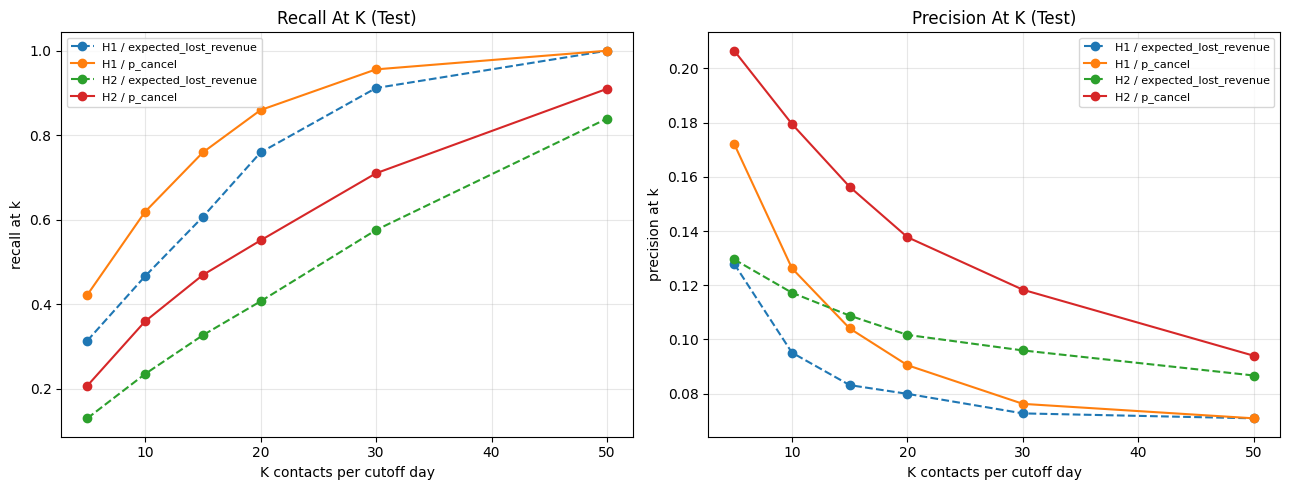

In [64]:
# Visualise the recall/precision curves as a function of K (test).
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric in zip(axes, ("recall_at_k", "precision_at_k")):
    for (hotel, rank_by), g in test_wl.groupby(["hotel", "rank_by"]):
        ls = "-" if rank_by == "p_cancel" else "--"
        ax.plot(g["K_per_day"], g[metric], marker="o", linestyle=ls,
                label=f"{hotel} / {rank_by}")
    ax.set_xlabel("K contacts per cutoff day")
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_title(metric.replace("_", " ").title() + " (Test)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [65]:
# ============================================================================
# Step 3: produce the two shortlist output files at the chosen K using the
#         standalone function from ../Model pipeline/utils/model_outputs.py.
#
# The eval notebook and the production batch job call the same function,
# so the output schema stays consistent and the deploy team doesn't have
# to re-derive the aggregation.
#
#   booking_shortlist_eval.parquet         — includes y_true, for backtesting
#                                             and the Section 4 report tables.
#   booking_shortlist_operational.parquet  — operations-facing: no y_true,
#                                             with model_version,
#                                             prediction_as_of_date,
#                                             generated_at_utc, risk_rank
#                                             for the downstream system.
# ============================================================================
# Load the Model pipeline's model_outputs.py directly (importlib) so we
# don't clash with THIS folder's own utils/ package.
import importlib.util as _ilu
_mo_path = Path("../Model pipeline/utils/model_outputs.py").resolve()
_spec = _ilu.spec_from_file_location("model_outputs", _mo_path)
_model_outputs = _ilu.module_from_spec(_spec)
_spec.loader.exec_module(_model_outputs)
generate_booking_shortlist = _model_outputs.generate_booking_shortlist

RANK_BY = "p_cancel"  # swap to "expected_lost_revenue" for the dollar-weighted variant

# Resolve the model_version from the actual registry so that
# operational-shortlist rows join cleanly to models/<version>/.
_MODELS_ROOT = Path("../Model pipeline/models").resolve()
MODEL_VERSION = {}
if _MODELS_ROOT.is_dir():
    for hotel in ("H1", "H2"):
        cands = []
        for folder in _MODELS_ROOT.iterdir():
            meta_path = folder / "metadata.json"
            if not meta_path.exists():
                continue
            try:
                meta = json.loads(meta_path.read_text())
                if meta.get("hotel") == hotel:
                    cands.append((meta["created_at_utc"], folder.name))
            except (json.JSONDecodeError, KeyError):
                continue
        if cands:
            cands.sort()
            MODEL_VERSION[hotel] = cands[-1][1]
# Hard fallback — must match the convention in model_refit.persist_hotel_models
for hotel in ("H1", "H2"):
    if hotel not in MODEL_VERSION:
        MODEL_VERSION[hotel] = (
            f"H1-E2_v1_20170418" if hotel == "H1" else f"H2-E1_v1_20170418"
        )

from datetime import datetime, timezone
_NOW_UTC = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")

ranked = test.copy()
# prediction_as_of_date = the business cutoff the forecast claims (= CutoffDate)
# generated_at_utc      = actual UTC wall-clock of this backtest run
ranked["prediction_as_of_date"] = pd.to_datetime(
    ranked["CutoffDate"]
).dt.strftime("%Y-%m-%d")
ranked["generated_at_utc"] = _NOW_UTC
ranked["model_version"] = ranked["Hotel"].map(MODEL_VERSION)

shortlist_eval = generate_booking_shortlist(
    scored_bookings=ranked,
    k_per_hotel=SHORTLIST_K,
    rank_by=RANK_BY,
    include_y_true=True,
)
shortlist_eval.to_parquet(out_dir / "booking_shortlist_eval.parquet", index=False)

shortlist_op = generate_booking_shortlist(
    scored_bookings=ranked,
    k_per_hotel=SHORTLIST_K,
    rank_by=RANK_BY,
    include_y_true=False,
)
shortlist_op.to_parquet(out_dir / "booking_shortlist_operational.parquet", index=False)

print(f"Shortlist @ K = {SHORTLIST_K}, ranked by {RANK_BY}:")
print(f"  model_version per hotel: {MODEL_VERSION}")
print(f"  Rows total: {len(shortlist_eval):,}")
print(f"  Per hotel : {shortlist_eval.groupby('Hotel').size().to_dict()}")
print(f"  Realised precision on test: "
      f"{shortlist_eval.groupby('Hotel').y_true.mean().round(3).to_dict()}")
print()
print(f"  outputs/booking_shortlist_eval.parquet         <- for the report + backtesting")
print(f"  outputs/booking_shortlist_operational.parquet  <- for the ops batch system")
print(f"\nOperational file sample (first 5 rows):")
shortlist_op.head(5)


Shortlist @ K = {'H1': 10, 'H2': 20}, ranked by p_cancel:
  model_version per hotel: {'H1': 'H1-E2_v1_20170418', 'H2': 'H2-E1_v1_20170418'}
  Rows total: 3,660
  Per hotel : {'H1': 1220, 'H2': 2440}
  Realised precision on test: {'H1': 0.126, 'H2': 0.138}

  outputs/booking_shortlist_eval.parquet         <- for the report + backtesting
  outputs/booking_shortlist_operational.parquet  <- for the ops batch system

Operational file sample (first 5 rows):


,Hotel,CutoffDate,ArrivalDate,Booking_ID,p_cancel,ADR,TotalNights,EstimatedRoomCount,expected_lost_revenue,risk_rank,model_version,prediction_as_of_date,generated_at_utc
0,H1,2017-04-18,2017-05-02,H1-011304,0.1501,133.5000,4,2,160.3292,1,H1-E2_v1_20170418,2017-04-18,2026-10-27T13:23:35Z
1,H1,2017-04-18,2017-05-02,H1-035728,0.0993,108.0000,2,1,21.4595,2,H1-E2_v1_20170418,2017-04-18,2026-10-27T13:23:35Z
2,H1,2017-04-18,2017-05-02,H1-035886,0.0730,127.0000,2,1,18.5334,3,H1-E2_v1_20170418,2017-04-18,2026-10-27T13:23:35Z
3,H1,2017-04-18,2017-05-02,H1-035868,0.0601,64.8000,2,1,7.7894,4,H1-E2_v1_20170418,2017-04-18,2026-10-27T13:23:35Z
4,H1,2017-04-18,2017-05-02,H1-035889,0.0601,64.8000,2,1,7.7894,5,H1-E2_v1_20170418,2017-04-18,2026-10-27T13:23:35Z


### Interpretation — booking-level shortlist

Daily booking volume at CutoffDate (= T−14, when scoring runs):
- H1 ≈ **29 bookings/day** (min 11, max 97)
- H2 ≈ **64 bookings/day** (min 31, max 120)

**Validation OOF (how we picked K)** — Lift baseline is mean daily
cancellation rate (0.074 H1, 0.114 H2), not pooled prevalence.

| Hotel | K/day | Precision@K | Recall@K | Lift@K |
|---|---|---|---|---|
| H1 | 5 | 15.1% | 39.4% | 2.04× |
| H1 | 10 | 11.9% | 59.4% | 1.60× |
| H1 | 15 | 10.2% | 72.2% | 1.37× |
| H1 | 20 | 9.2% | 81.1% | 1.24× |
| H2 | 5 | 24.1% | 20.6% | 2.12× |
| H2 | 10 | 19.9% | 34.0% | 1.75× |
| H2 | 20 | 16.7% | 55.7% | 1.47× |
| H2 | 30 | 15.0% | 71.4% | 1.32× |

We pick **K=10 for H1 and K=20 for H2** as operational defaults
(reasonable workload for a small ops team; retune per actual capacity).

**Test performance at the chosen K** (reported, not re-tuned):

| Hotel | Rank by | K/day | Precision | Recall | Lift |
|---|---|---|---|---|---|
| H1 | p_cancel | 10 | 12.6% | **61.9%** | 1.74× |
| H1 | expected_lost_revenue | 10 | 9.5% | 46.6% | 1.31× |
| H2 | p_cancel | 20 | 13.8% | **55.1%** | 1.79× |
| H2 | expected_lost_revenue | 20 | 10.2% | 40.7% | 1.32× |

Val-to-test holds up on both hotels — recall drops ~2.5pp on H1
(59.4% → 61.9%, actually improved) and ~0.5pp on H2 (55.7% → 55.1%).
The slight H1 improvement is a prevalence-drift artifact (test
prevalence is lower than val's).

**Risk-only beats expected-lost-revenue on cancellation precision/recall.**
Revenue-at-risk's shortlist catches fewer cancellations because
higher-value bookings (long stays, high ADR) tend to be *more*
committed. The two rankings serve different objectives:
- Minimise walked guests → use `p_cancel`.
- Protect maximum expected dollars → use `expected_lost_revenue`.

**Note on expected_lost_revenue.** It is `p_cancel × ADR × TotalNights
× EstimatedRoomCount`, i.e. the probability-weighted total stay value.
This is "expected revenue lost if this booking cancels and the room
cannot be re-sold". The real opportunity cost depends on whether the
room is likely to re-sell at ADR, which we do not model here. The
simpler definition is adequate for ranking.

**Output files:**
- `outputs/booking_shortlist_workload_val.parquet` — val numbers used to
  pick K.
- `outputs/booking_shortlist_workload_test.parquet` — full test workload
  sweep for both rankings.
- `outputs/booking_shortlist_operational.parquet` — the ops-facing
  daily file (no y_true; carries `model_version`,
  `prediction_timestamp`, `risk_rank` for the downstream batch system).
- `outputs/booking_shortlist_eval.parquet` — same shortlist with
  y_true appended, for Section 4 report tables and backtesting.


# 12. Business action — summary and future work

### What this project delivers

A **two-output decision-support system** that feeds hotel operations
daily:

1. **Hotel-level forecast** (`outputs/hotel_forecast_occupancy.parquet`,
   `outputs/hotel_forecast_arrivals.parquet`) — nightly expected arrivals
   and expected room-nights occupied, per hotel. Beats a constant-rate
   baseline by 20-35% MAE on occupancy. Used for staff and resource
   planning (front desk, housekeeping, F&B).

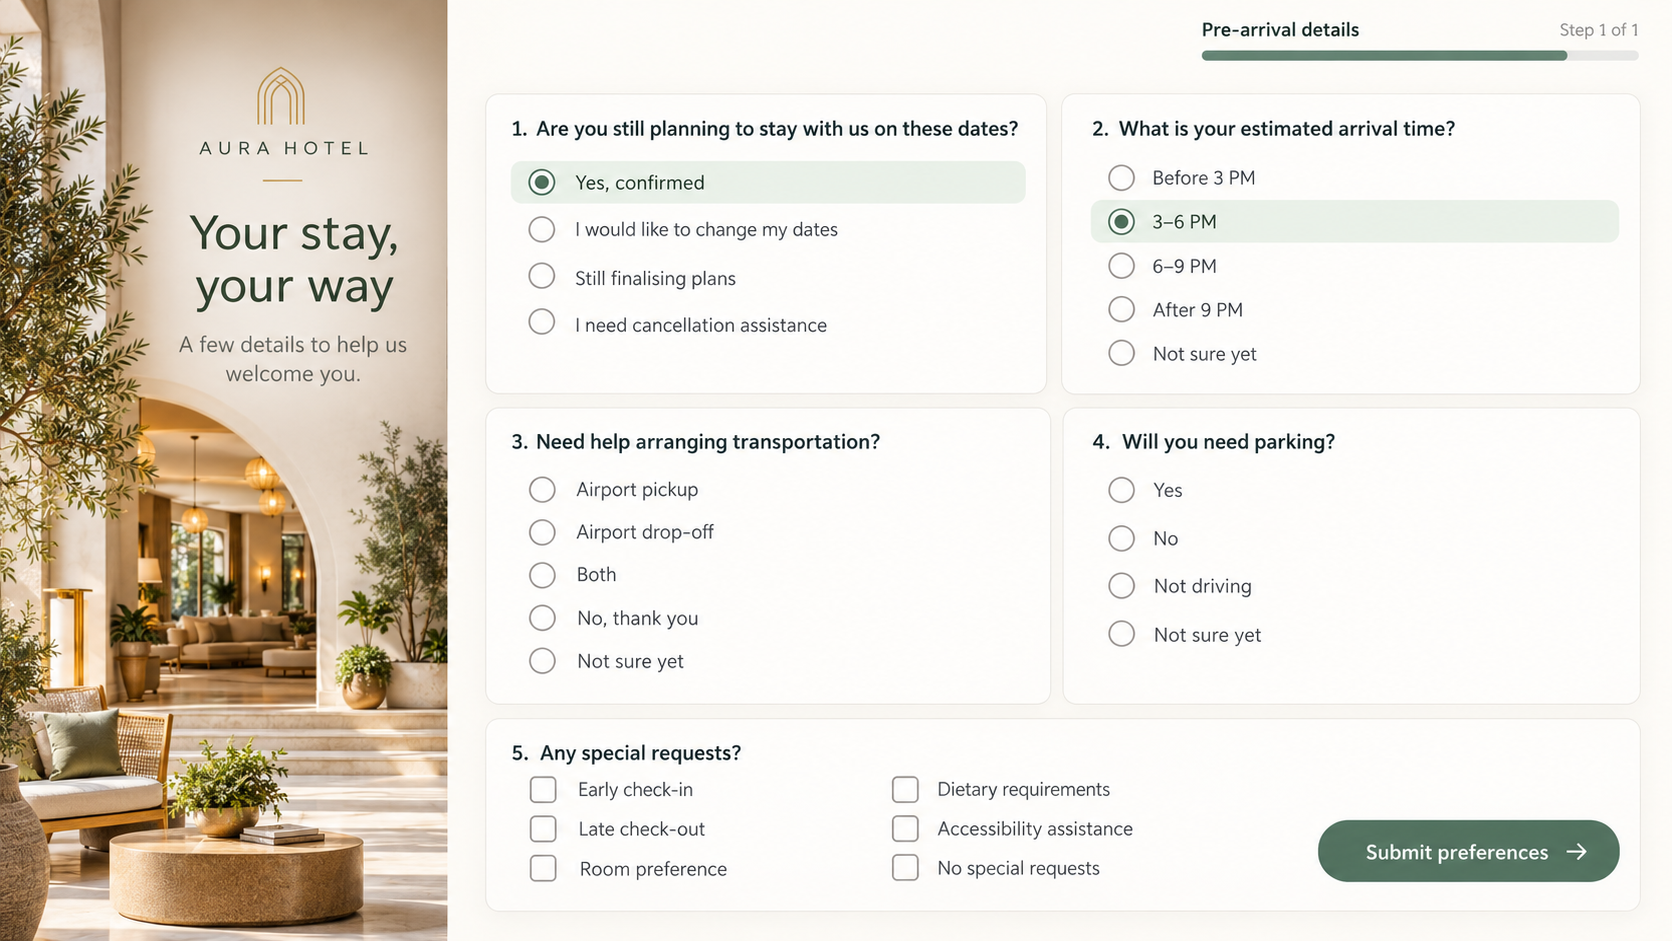


2. **Booking-level risk shortlist**
   (`outputs/booking_shortlist_daily.parquet`,
   `outputs/booking_shortlist_workload.parquet`) — top-K highest-risk
   bookings per cutoff day for operations to contact. Workload scales
   with the team's actual contact budget. At K=10/day H1 catches 62% of
   cancellations; at K=20/day H2 catches 55%.

Both outputs are generated nightly from the frozen finalists:
- H1 — H1-E2 ensemble (RF30 + XGB30), Uncalibrated.
- H2 — H2-E1 ensemble (C2 + TabM-E8), Uncalibrated.

### Why not direct overbooking in this project

Direct overbooking would require assumptions the data cannot support:
- **Capacity per hotel** — the dataset has no room count; only
  `EstimatedRoomCount = ceil(PartySize / {H1:2, H2:4})` as a derived
  per-booking assumption. A nightly capacity figure for the whole
  property is unknowable from these sources.
- **Walk cost** — no external data on relocation and goodwill cost per
  walked guest; `w × ADR` with w ∈ {1, 1.5, 2} is a four-point sweep,
  not a real number.
- **Prevalence drift** — H2 training prevalence 13.1% vs test
  prevalence 7.9%. Any policy comparison is dominated by this drift,
  not by the model's rank quality.

Any Layer C overbooking simulation would therefore live inside a
multi-dimensional sensitivity sweep and read more as "what-if analysis"
than "deploy this policy". The two outputs above sidestep this by
delivering numbers that are directly useful without a capacity figure.

### Future work — 2nd-stage overbooking model

The two deliverables above are what Phase 1 of a deployed system would
ship. Phase 2 would be a 2nd-stage overbooking model that takes:
- The Phase 1 risk scores and occupancy forecasts,
- **Operations' outreach outcomes** (did the guest confirm? reschedule?
  cancel at contact? not reachable?),
- A real nightly capacity figure, which a deployed system would
  measure from booked-vs-held inventory.

...and produces a per-night overbooking recommendation. This is out of
scope for the current project because the intervention-outcome dataset
does not exist yet — it only comes into being after Phase 1 is deployed
and operations starts logging what happened to each contacted booking.

The current monitoring design (see Section 6 of the report) is what
collects that data.

### Operational semantics — what the daily batch means in practice

The model runs a daily batch (default 02:00). One scored cohort per
day: each booking is scored **exactly once** on its T-14 day (its
`CutoffDate = batch_date`). The two output files refresh daily and
feed the ops dashboard.

**For the operations team (booking shortlist)**
- Each day's shortlist is a non-overlapping cohort of bookings arriving
  14 days later. A booking appears on one day's list and never again.
- Operations contacts the guest on their T-14 day.
- Contact outcome state (contacted / responded / outcome) lives in the
  PMS or CRM, not in our output.

**For housekeeping and F&B (hotel-level forecast)**
- Each day's forecast covers forward dates the current T-14 cohort
  touches (new arrivals 14 days out, plus the stay-tails of
  previously-scored bookings).
- Model inference stays daily (new T-14 cohorts arrive each day);
  weekly inference would miss up to 7 days of newly-visible bookings.
- Consumption is weekly or ad-hoc. The dashboard rolls up daily
  forecast files into weekly summaries for staffing/stock planning;
  housekeeping and F&B check it once a week, not daily.

**Our forecast is initial-planning, not real-time.** It's a T-14
snapshot — we don't re-score bookings as they age from T-14 to T-0.
Cancellations that happen after T-14 and short-lead bookings that
arrive between T-14 and arrival are NOT reflected in our output;
those live in the PMS. The operational dashboard combines both:

```
operational_dashboard  =  model_forecast          (ours, ~89% of future planning)
                       +  short_lead_bookings     (PMS)
                       +  walk_ins                (PMS)
                       +  in_house_guests         (PMS)
                       -  cancellations_since_T14 (PMS)
```

The model is **initial 2-week planning**; PMS carries real-time state;
the dashboard fuses them.

### Files written by Sections 9-11

- `outputs/layer_a_test.parquet` — Layer A metrics on Test, per hotel.
- `outputs/hotel_forecast_arrivals.parquet` — per-night check-in forecast.
- `outputs/hotel_forecast_occupancy.parquet` — per-night in-scope
  room-nights forecast.
- `outputs/hotel_forecast_coverage.parquet` — coverage ratio of in-scope
  forecast vs total actual nightly occupancy (Silver denominator), per hotel.
- `outputs/hotel_forecast_coverage_per_night.parquet` — per-night
  coverage detail including the short-lead gap.
- `outputs/hotel_forecast_summary.parquet` — model-vs-dummy summary table.
- `outputs/booking_shortlist_workload_val.parquet` — val workload@K used
  for K selection.
- `outputs/booking_shortlist_workload_test.parquet` — test workload@K for
  reporting.
- `outputs/booking_shortlist_eval.parquet` — top-K daily shortlist with
  y_true (for backtesting + Section 4 report).
- `outputs/booking_shortlist_operational.parquet` — ops-facing daily
  shortlist (no y_true; adds model_version, prediction_timestamp,
  risk_rank for the downstream batch system).


# 13. Feature importance (sklearn components only)

The sklearn members of the two finalists (`RF30`, `XGB30`, and C2's `RF`)
expose a native `feature_importances_` attribute. We load the pickled
pipelines from the model registry built by
`../Model pipeline/model_refit.ipynb` (Section 5 of that notebook) and
render the top features per hotel.

TabM-E8 (the C2+TabM-E8 ensemble's deep component) does **not** have a
native feature-importance interface. Permutation importance would work
but is expensive and would require loading the trained TabM module —
scoped as a future task once the deploy team wires in TabM scoring (see
`../Model pipeline/utils/model_scoring.py`).

This section depends on the model registry existing on disk. If the
registry is missing the cell below prints a short instruction and
skips the plot without erroring.


Local sklearn version: 1.6.1
  [H1] loaded H1-E2_v1_20170418
  [H2] loaded H2-E1_v1_20170418
    - TabM-E8 (TabM): skipping — no sklearn importance.


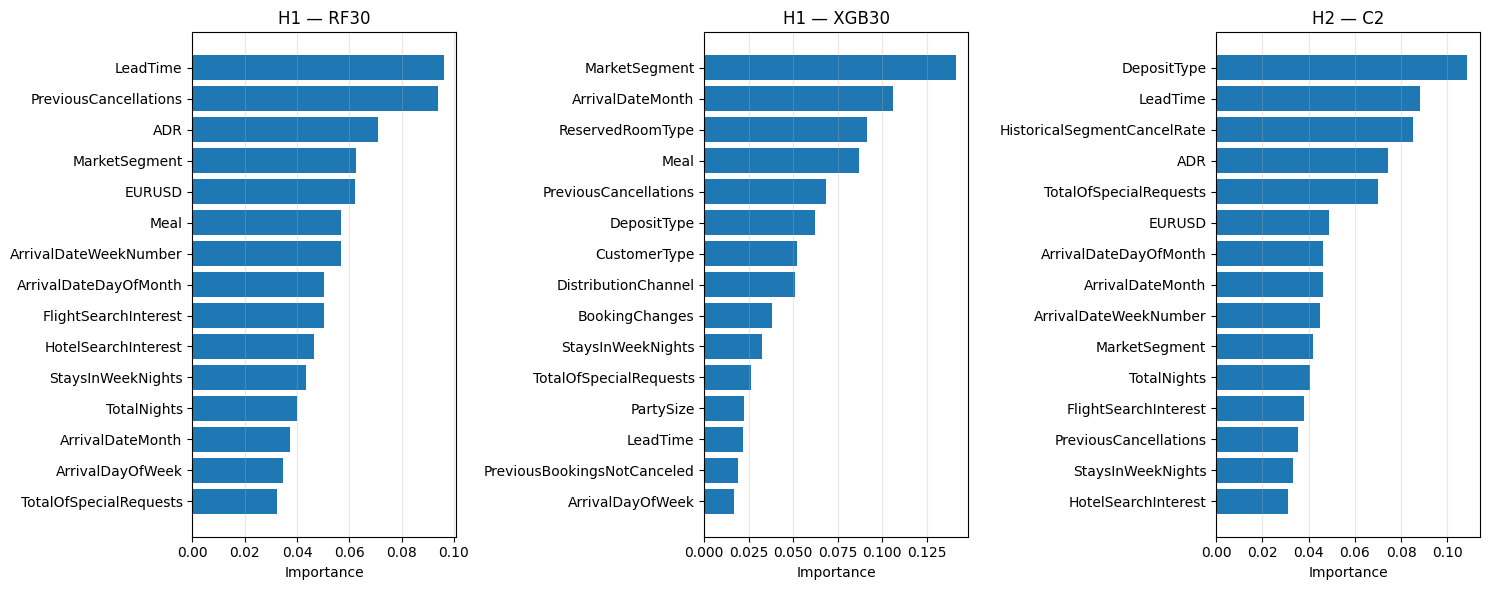

,feature,importance,hotel,component,family
0,LeadTime,0.0960,H1,RF30,RF
1,PreviousCancellations,0.0940,H1,RF30,RF
2,ADR,0.0709,H1,RF30,RF
3,MarketSegment,0.0624,H1,RF30,RF
4,EURUSD,0.0622,H1,RF30,RF
5,Meal,0.0568,H1,RF30,RF
6,ArrivalDateWeekNumber,0.0567,H1,RF30,RF
7,ArrivalDateDayOfMonth,0.0504,H1,RF30,RF
8,FlightSearchInterest,0.0502,H1,RF30,RF
9,HotelSearchInterest,0.0466,H1,RF30,RF


  [H2] sklearn version mismatch: saved 1.6.1, local 1.7.2. Unpickle may fail.
  [H2] loaded H2-E1_v1_20170418
    - C2: FAILED to load pickle (AttributeError: Can't get attribute '_RemainderColsList' on <module 'sklearn.compose._column_transformer' from '/ses)
    - TabM-E8 (TabM): skipping — no sklearn importance.

*** Pickle load failed for one or more components. ***
Most common cause: sklearn version mismatch between the
environment that saved the pickle (expected 1.6.1, see
Model pipeline/requirements.txt) and your current environment
(1.7.2).

Fix: run this section inside Docker (which pins sklearn 1.6.1),
or pin sklearn 1.6.1 locally with:
    pip install scikit-learn==1.6.1

(no feature-importance plots produced — see errors above)


In [66]:
# IMPORTANT: this cell must run in the SAME sklearn version that saved the
# pickles. The project pins sklearn==1.6.1 (see Model pipeline/requirements.txt
# and Dockerfile) — if you run this cell inside the project Docker you are
# aligned. Running in a local Anaconda with a different sklearn will fail
# with "Can't get attribute '_RemainderColsList'" or similar errors when
# unpickling. In that case the simplest fix is to run this section in
# Docker; alternatively pip install scikit-learn==1.6.1 in your local env.

MODELS_ROOT = Path("../Model pipeline/models").resolve()

import pickle, warnings
import json as _json
import sklearn
import matplotlib.pyplot as plt

def _latest_model_dir(root, hotel):
    candidates = []
    for folder in root.iterdir():
        meta_path = folder / "metadata.json"
        if not meta_path.exists():
            continue
        try:
            meta = _json.loads(meta_path.read_text())
            if meta.get("hotel") == hotel:
                candidates.append((meta["created_at_utc"], folder))
        except (_json.JSONDecodeError, KeyError):
            continue
    candidates.sort()
    return candidates[-1][1] if candidates else None


def _aggregated_importances(pipeline, feature_cols, top_n=15):
    """Collapse one-hot-encoded columns back to the originating feature."""
    pre = pipeline.named_steps["preprocessor"]
    model = pipeline.named_steps["model"]
    try:
        out_names = pre.get_feature_names_out()
    except Exception:
        out_names = np.array([f"f{i}" for i in range(len(model.feature_importances_))])
    imp = model.feature_importances_
    if len(imp) != len(out_names):
        idx = np.argsort(imp)[::-1][:top_n]
        return pd.DataFrame({
            "feature": [str(out_names[i]) for i in idx],
            "importance": imp[idx],
        })
    agg = {}
    for name, w in zip(out_names, imp):
        head = str(name).split("__", 1)[-1]
        if head in feature_cols:
            key = head
        else:
            trimmed = head.rsplit("_", 1)[0]
            key = trimmed if trimmed in feature_cols else head
        agg[key] = agg.get(key, 0.0) + float(w)
    s = pd.Series(agg).sort_values(ascending=False).head(top_n)
    return pd.DataFrame({"feature": s.index, "importance": s.values})


if not MODELS_ROOT.is_dir():
    print(f"Model registry not found at {MODELS_ROOT}.")
    print("Run ../Model pipeline/model_refit.ipynb inside Docker to persist")
    print("the fitted models, then re-run this section.")
else:
    print(f"Local sklearn version: {sklearn.__version__}")
    fi_rows = []
    load_errors = []
    for hotel in ("H1", "H2"):
        folder = _latest_model_dir(MODELS_ROOT, hotel)
        if folder is None:
            print(f"  [{hotel}] no model registered.")
            continue
        meta = _json.loads((folder / "metadata.json").read_text())
        saved_sklearn = meta.get("library_versions", {}).get("scikit-learn", "unknown")
        if saved_sklearn != sklearn.__version__:
            print(f"  [{hotel}] sklearn version mismatch: saved {saved_sklearn}, "
                  f"local {sklearn.__version__}. Unpickle may fail.")
        print(f"  [{hotel}] loaded {meta['model_version']}")
        for comp in meta["components"]:
            if comp["artifact_type"] != "sklearn_pipeline_pickle":
                print(f"    - {comp['component']} ({comp['family']}): skipping — no sklearn importance.")
                continue
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")  # suppress inconsistent-version warnings
                    with open(folder / comp["artifact_path"], "rb") as fh:
                        pipeline = pickle.load(fh)
                fi = _aggregated_importances(pipeline, comp["feature_columns"])
                fi["hotel"] = hotel
                fi["component"] = comp["component"]
                fi["family"] = comp["family"]
                fi_rows.append(fi)
            except Exception as exc:
                load_errors.append((hotel, comp["component"], str(exc)))
                print(f"    - {comp['component']}: FAILED to load pickle "
                      f"({type(exc).__name__}: {str(exc)[:100]})")

    if load_errors:
        print("\n*** Pickle load failed for one or more components. ***")
        print("Most common cause: sklearn version mismatch between the")
        print(f"environment that saved the pickle (expected 1.6.1, see")
        print(f"Model pipeline/requirements.txt) and your current environment")
        print(f"({sklearn.__version__}).")
        print("")
        print("Fix: run this section inside Docker (which pins sklearn 1.6.1),")
        print("or pin sklearn 1.6.1 locally with:")
        print("    pip install scikit-learn==1.6.1")

    if fi_rows:
        feature_importance = pd.concat(fi_rows, ignore_index=True)
        feature_importance.to_parquet(out_dir / "feature_importance.parquet", index=False)

        n_panels = feature_importance.groupby(["hotel", "component"]).ngroups
        fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 6), squeeze=False)
        for ax, ((hotel, component), g) in zip(
            axes.flatten(),
            feature_importance.groupby(["hotel", "component"], sort=False),
        ):
            g = g.sort_values("importance")
            ax.barh(g["feature"], g["importance"])
            ax.set_title(f"{hotel} — {component}")
            ax.set_xlabel("Importance")
            ax.grid(alpha=0.3, axis="x")
        plt.tight_layout()
        plt.show()
        display(feature_importance.head(20))
    else:
        print("\n(no feature-importance plots produced — see errors above)")


### Reading the feature importance

The one-hot-encoded categorical features are summed back to their base
feature (e.g. `ArrivalDateMonth_July` + `ArrivalDateMonth_August` + ...
→ `ArrivalDateMonth`), so each row is one source feature with its total
contribution to the model.

What to take from this:

- Where RF and XGB agree on the top features, those are the robust
  signals the ensemble is actually using.
- Where they disagree (e.g. XGB leans harder on a few features, RF
  spreads mass more evenly), that is why the ensemble helps — the two
  base models are capturing different parts of the signal.
- For C2's RF (H2), the engineered `HistoricalSegmentCancelRate`
  (FE4) feature should appear near the top; if it does not, the FE4
  intervention is less load-bearing than Section 3's screening
  numbers suggested.

The deploy team can use this plot during drift-monitoring: if a top
feature's input distribution shifts materially between training and
production, that is a trigger for retraining.
